# Comparing S(Z, z) of TNG simulations across resolution/box size

## S(z) and S(Z):

In [81]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck15  as cosmo #Planck 2015 since that's what TNG uses
import seaborn as sns
from math import ceil
import matplotlib.ticker as ticker

# Custom scripts
sys.path.append('../')
import get_ZdepSFRD as Z_SFRD
from TNG_BBHpop_properties import read_best_fits
from Fit_model_TNG_SFRD import readTNGdata, interpolate_TNGdata
from compare_SFRDparams import compare_SFR, compare_Zdist

## PLOT setttings
plt.rc('font', family='serif')
import matplotlib
plt.rc('font', family='serif', weight='bold')
plt.rc('text', usetex=True)
matplotlib.rcParams['font.weight']= 'bold'
matplotlib.rcParams.update({'font.weight': 'bold'})
import MassDistHelperFunctions as mfunc

In [ ]:
path = '/Users/sashalvna/Research/Fit_SFRD_TNG/data/'
tngs=['TNG50-1', 'TNG50-2', 'TNG50-3', 'TNG100-1', 'TNG100-2', 'TNG300-1'] 
vers = [1, 2, 3, 1, 2, 1, 2]
Zsun = 0.014

data_colors_tng = ['#40E9E0', '#1C7EB7', "#00446E",'#F76FDD', "#900849", '#98CB4F', "#589019", 'black', 'gray', 'lightgray']
data_colors_all = [ '#CC6677', '#999933', '#117733',  '#88CCEE', '#332288', '#AA4499']
z_order= [7, 6, 5, 4, 3, 2, 1]
line_styles = ['solid', 'dashed', 'dotted']

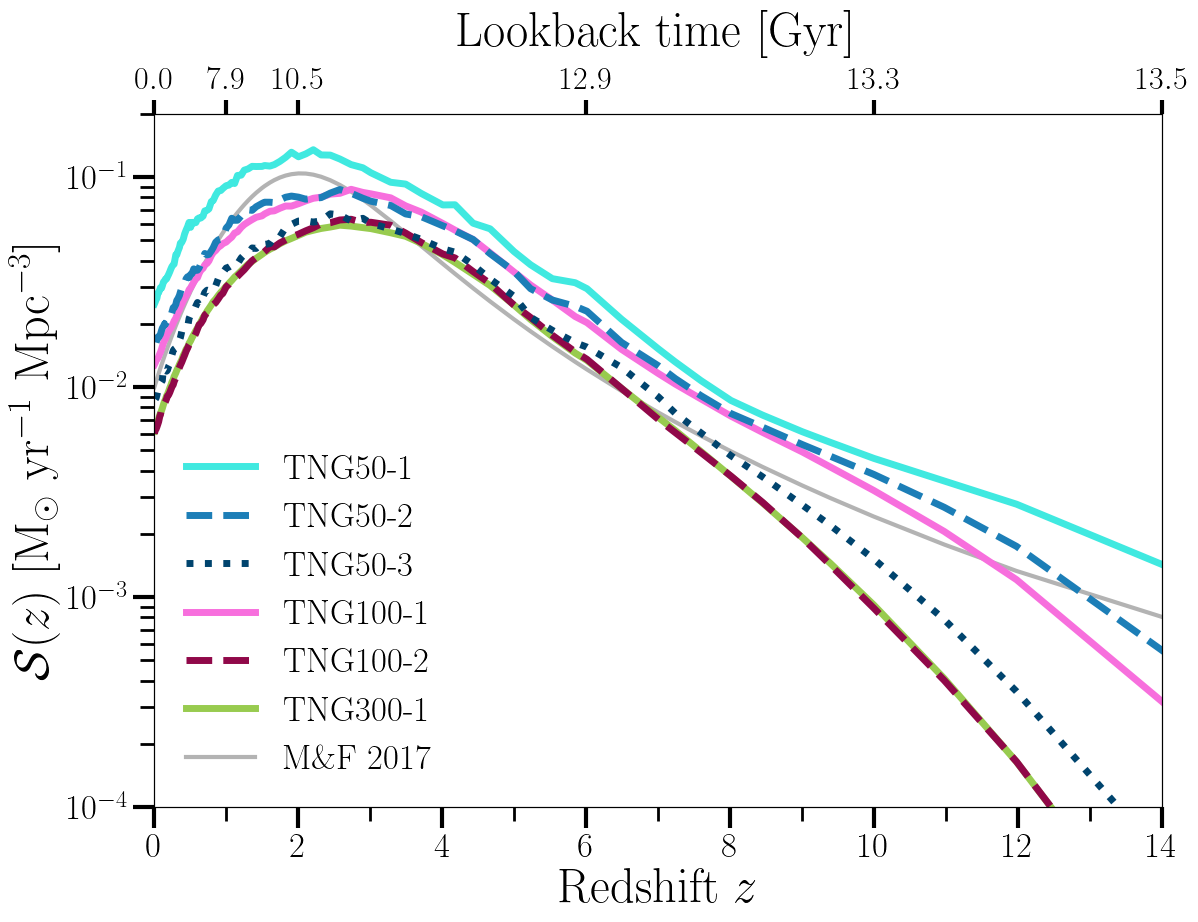

In [84]:
# S(z)

compare_SFR(path, tngs, vers, plotmodel=False, plotredshift=True, xlim=[0, 14], ylim=[10**-4, 2e-1], 
                 showfractionalerr=False, plotlogscale=True, transparent=True, data_colors=data_colors_tng)

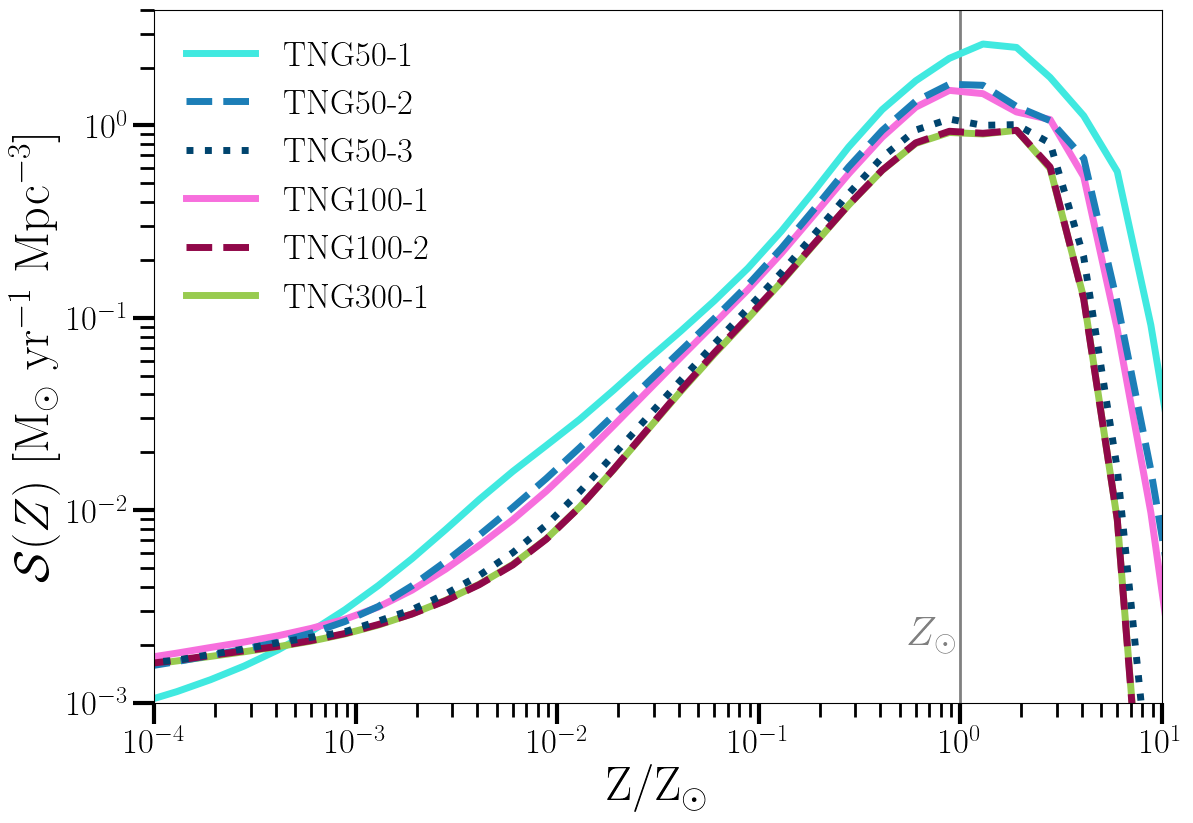

In [68]:
# S(Z)

compare_Zdist(path, tngs, vers, xlim=[10**-4, 10], ylim=[1e-3, 4], #error_ylim=[1e-1, 1e3], 
                  plotmodel=False, plotlogscale=True, showfractionalerr=False, transparent=True,  data_colors=data_colors_tng)

## Comparing TNGs

In [69]:
#read in S(Z, z) for each TNG

SFRDs = []
S_z = []
S_Z = []
Lookbacktimes = []
Redshifts = []
Zbins = []
step_logZ = []

for tng in tngs:

    if 'TNG50' in tng:
        rbox=35
    elif 'TNG100' in tng:
        rbox=75
    elif 'TNG30' in tng:
        rbox=205

    #Plot the TNG data
    try:
        Sim_SFRD, Sim_Lookbacktimes, Sim_Redshifts, Sim_center_Zbin, step_fit_logZ  = readTNGdata(tng, loc = path+'SFRMetallicityFromGasWithMetals%s.hdf5'%(tng), rbox=rbox, SFR=False, metals=False)
    except:
        Sim_SFRD, Sim_Lookbacktimes, Sim_Redshifts, Sim_center_Zbin, step_fit_logZ  = readTNGdata(tng, loc = path+'SFRMetallicityFromGas%s.hdf5'%tng, rbox=rbox, SFR=False, metals=False)


    S_z.append(np.sum(Sim_SFRD, axis=1)*step_fit_logZ)
    S_Z.append(np.sum(Sim_SFRD, axis=0))
    SFRDs.append(Sim_SFRD)
    Lookbacktimes.append(Sim_Lookbacktimes)
    Redshifts.append(Sim_Redshifts)
    Zbins.append(Sim_center_Zbin)
    step_logZ.append(step_fit_logZ)


/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/2012342553.py:30: RuntimeWarning: divide by zero encountered in divide
  ax[0,0].plot(Redshifts[0], S_z[3]/S_z[4], lw=4, c=data_colors_all[1], label='%s/%s, same box size'%(tngs[3], tngs[4]), zorder=5)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/2012342553.py:52: RuntimeWarning: divide by zero encountered in divide
  ax[1,0].plot(Redshifts[0], (S_z[3]-S_z[4])/S_z[4]*100, lw=4, c=data_colors_all[1], zorder=5)#label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/2012342553.py:78: RuntimeWarning: invalid value encountered in divide
  ax[0,1].plot(Zbins[0]/Zsun, S_Z[4]/S_Z[5], lw=4, c=data_colors_all[0],  zorder=6)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/2012342553.py:79: RuntimeWarning: divide by zero encountered in divide
  ax[0,1].plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1],  zorder=5)
/var/

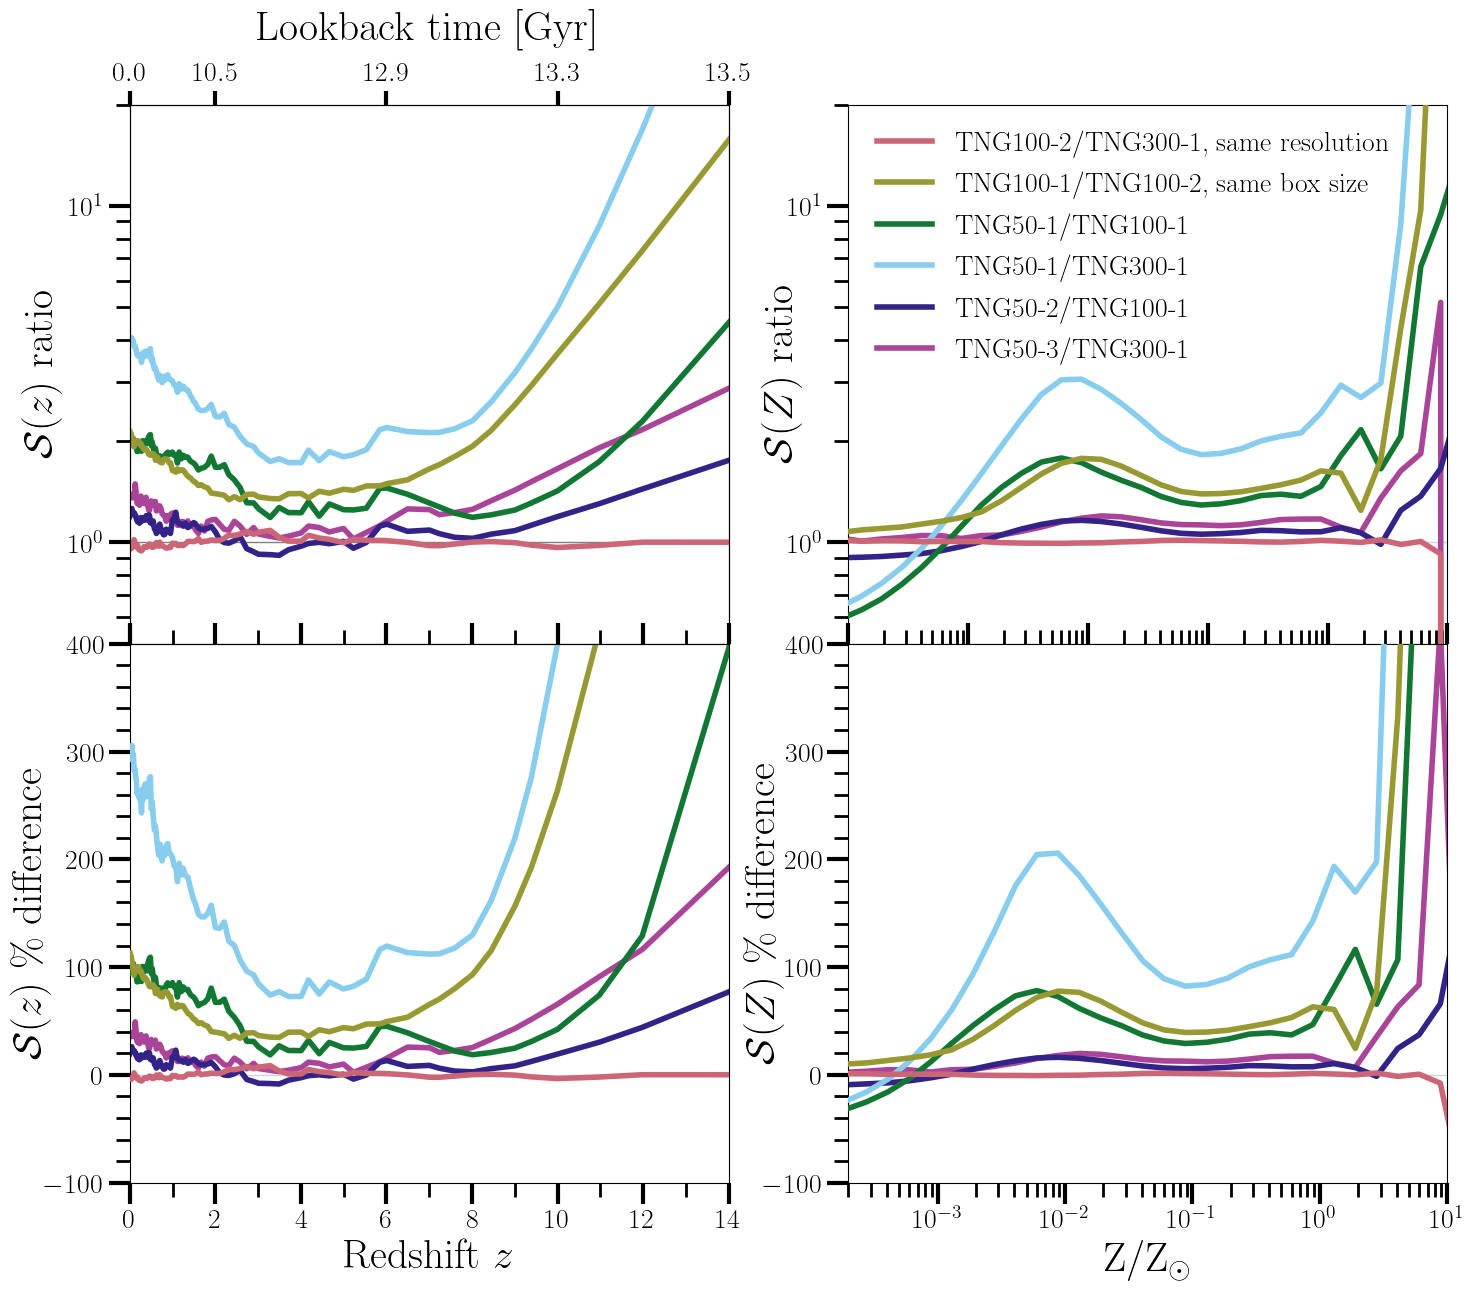

In [70]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize = (17,14))
fig.subplots_adjust(hspace=0)

#############################################
#S(z) ratio
ax[0,0].axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1
ax[0,0].tick_params(axis='both', which='major', labelsize=20) 
ax[0,0].xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[0,0].tick_params(length=15, width=3, which='major')
ax[0,0].tick_params(length=10, width=2, which='minor')
ax[0,0].tick_params(axis='x', which='major', direction='in') 
ax[0,0].tick_params(axis='x', which='minor', direction='in') 
ax[0,0].tick_params(axis='x',  which='both', labelbottom=False)
ax[0,0].set_ylabel(r'$\mathcal{S}(z)$ ratio', fontsize = 30, labelpad=5)
ax[0,0].set_yscale('log')

#set up second x axis
ax2 = ax[0,0].twiny()
redshift_tick_list = [0, 2, 6, 10, 14]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 20)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 30, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=20)
ax2.tick_params(length=10, width=3, which='major')

ax[0,0].set_xlim(0, 14)
ax2.set_xlim(0, 14) 
ax[0,0].set_ylim(5e-1, 2e1)
ax[0,0].plot(Redshifts[0], S_z[4]/S_z[5], lw=4, c=data_colors_all[0], label='%s/%s, same resolution'%(tngs[4], tngs[5]), zorder=6)
ax[0,0].plot(Redshifts[0], S_z[3]/S_z[4], lw=4, c=data_colors_all[1], label='%s/%s, same box size'%(tngs[3], tngs[4]), zorder=5)
ax[0,0].plot(Redshifts[0], S_z[0]/S_z[3], lw=4, c=data_colors_all[2], label='%s/%s'%(tngs[0], tngs[3]), zorder=4)
ax[0,0].plot(Redshifts[0], S_z[0]/S_z[5], lw=4, c=data_colors_all[3], label='%s/%s'%(tngs[0], tngs[5]), zorder=3)
ax[0,0].plot(Redshifts[0], S_z[1]/S_z[3], lw=4, c=data_colors_all[4], label='%s/%s'%(tngs[1], tngs[3]), zorder=2)
ax[0,0].plot(Redshifts[0], S_z[2]/S_z[5], lw=4, c=data_colors_all[5], label='%s/%s'%(tngs[2], tngs[5]), zorder=1)

#############################################
#S(z) percent error
ax[1,0].axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax[1,0].tick_params(axis='both', which='major', labelsize=20)
ax[1,0].tick_params(length=15, width=3, which='major')
ax[1,0].tick_params(length=10, width=2, which='minor')
ax[1,0].xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[1,0].yaxis.set_minor_locator(ticker.MultipleLocator(20))
ax[1,0].set_xlabel(r"Redshift $z$", fontsize = 30)
ax[1,0].set_ylabel(r'$\mathcal{S}(z)$ \% difference', fontsize = 30, labelpad=-5)

#Set limits for horizontal axis
ax[1,0].set_xlim(0, 14)
ax[1,0].set_ylim(-100, 400)

ax[1,0].plot(Redshifts[0], (S_z[4]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[0], zorder=6)# label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]), zorder=6)
ax[1,0].plot(Redshifts[0], (S_z[3]-S_z[4])/S_z[4]*100, lw=4, c=data_colors_all[1], zorder=5)#label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)
ax[1,0].plot(Redshifts[0], (S_z[0]-S_z[3])/S_z[3]*100, lw=4, c=data_colors_all[2], zorder=4)#label='(%s-%s)/%s'%(tngs[0], tngs[3], tngs[3]), zorder=4)
ax[1,0].plot(Redshifts[0], (S_z[0]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[3], zorder=3)#label='(%s-%s)/%s'%(tngs[0], tngs[5], tngs[5]), zorder=3)
ax[1,0].plot(Redshifts[0], (S_z[1]-S_z[3])/S_z[3]*100, lw=4, c=data_colors_all[4], zorder=2)#label='(%s-%s)/%s'%(tngs[1], tngs[3], tngs[3]), zorder=2)
ax[1,0].plot(Redshifts[0], (S_z[2]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[5], zorder=1)#label='(%s-%s)/%s'%(tngs[2], tngs[5], tngs[5]), zorder=1)

#############################################
#S(Z) ratio
Zsun = 0.014
ax[0,1].axhline(y=1, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax[0,1].tick_params(axis='both', which='major', labelsize=20)
ax[0,1].tick_params(length=15, width=3, which='major')
ax[0,1].tick_params(length=10, width=2, which='minor')
ax[0,1].tick_params(axis='x', which='major', direction='in')
ax[0,1].tick_params(axis='x', which='minor', direction='in')
ax[0,1].xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[0,1].yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[0,1].tick_params(axis='x',  which='both', labelbottom=False)
ax[0,1].set_ylabel(r'$\mathcal{S}(Z)$ ratio', fontsize = 30, labelpad=-10)
ax[0,1].set_xscale('log')
ax[0,1].set_yscale('log')

#Set limits for horizontal axis
ax[0,1].set_xlim(10**-4, 10)
ax[0,1].set_ylim(5e-1, 2e1)

ax[0,1].plot(Zbins[0]/Zsun, S_Z[4]/S_Z[5], lw=4, c=data_colors_all[0],  zorder=6)
ax[0,1].plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1],  zorder=5)
ax[0,1].plot(Zbins[0]/Zsun, S_Z[0]/S_Z[3], lw=4, c=data_colors_all[2],  zorder=4)
ax[0,1].plot(Zbins[0]/Zsun, S_Z[0]/S_Z[5], lw=4, c=data_colors_all[3],  zorder=3)
ax[0,1].plot(Zbins[0]/Zsun, S_Z[1]/S_Z[3], lw=4, c=data_colors_all[4],  zorder=2)
ax[0,1].plot(Zbins[0]/Zsun, S_Z[2]/S_Z[5], lw=4, c=data_colors_all[5],  zorder=1)

#############################################
#S(Z) percent error
ax[1,1].axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax[1,1].tick_params(axis='both', which='major', labelsize=20)
ax[1,1].tick_params(length=15, width=3, which='major')
ax[1,1].tick_params(length=10, width=2, which='minor')
ax[1,1].xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[1,1].yaxis.set_minor_locator(ticker.MultipleLocator(20))
ax[1,1].set_xlabel(r"Z/Z$_\odot$", fontsize = 30)
ax[1,1].set_ylabel(r'$\mathcal{S}(Z)$ \% difference', fontsize = 30, labelpad=-15)
ax[1,1].set_xscale('log')
ax[1,1].set_xscale('log')
ax[1,1].set_xlim(2e-4, 10)
ax[1,1].set_ylim(-100, 400)

ax[1,1].plot(Zbins[0]/Zsun, (S_Z[4]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[0], zorder=6)
ax[1,1].plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], zorder=5)
ax[1,1].plot(Zbins[0]/Zsun, (S_Z[0]-S_Z[3])/S_Z[3]*100, lw=4, c=data_colors_all[2], zorder=4)
ax[1,1].plot(Zbins[0]/Zsun, (S_Z[0]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[3], zorder=3)
ax[1,1].plot(Zbins[0]/Zsun, (S_Z[1]-S_Z[3])/S_Z[3]*100, lw=4, c=data_colors_all[4], zorder=2)
ax[1,1].plot(Zbins[0]/Zsun, (S_Z[2]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[5], zorder=1)

#fig.legend(fontsize = 25, frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, -0.08))
fig.legend(fontsize = 20, frameon=False, bbox_to_anchor=(0.88, 0.88))
fig.savefig('figures/compareSFRD_allTNGs.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')


/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/2512175454.py:30: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Redshifts[0], S_z[3]/S_z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]), zorder=5)


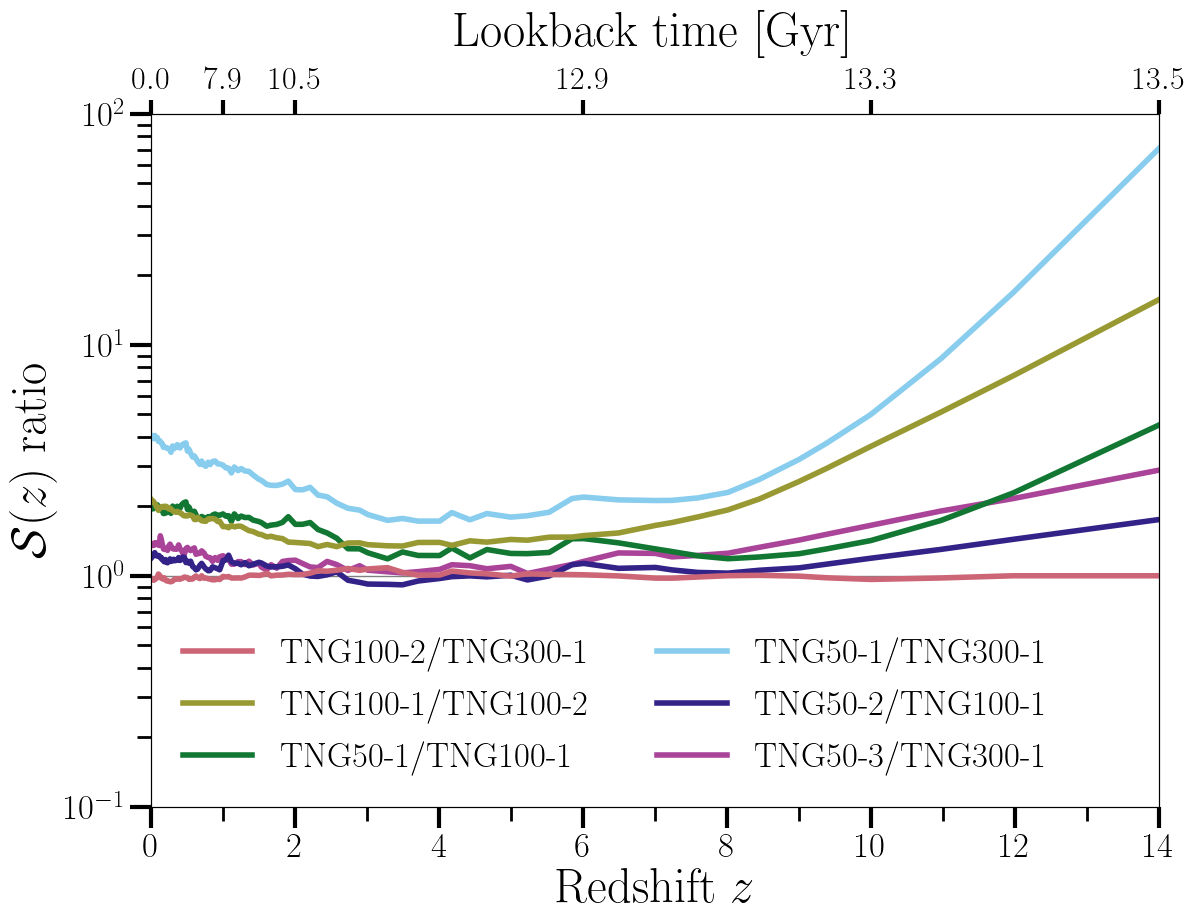

In [71]:
#S(z) ratios 

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
ax.axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25) 
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_ylabel(r'$\mathcal{S}(z)$ ratio', fontsize = 35)
ax.set_xlabel(r"Redshift $z$", fontsize = 35)
ax.set_yscale('log')

#set up second x axis
ax2 = ax.twiny()
redshift_tick_list = [0, 1, 2, 6, 10, 14]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')

#Set limits for horizontal axis
ax.set_xlim(0, 14)
ax2.set_xlim(0, 14) 
ax.set_ylim(1e-1, 1e2)

ax.plot(Redshifts[0], S_z[4]/S_z[5], lw=4, c=data_colors_all[0], label='%s/%s'%(tngs[4], tngs[5]), zorder=6)
ax.plot(Redshifts[0], S_z[3]/S_z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]), zorder=5)
ax.plot(Redshifts[0], S_z[0]/S_z[3], lw=4, c=data_colors_all[2], label='%s/%s'%(tngs[0], tngs[3]), zorder=4)
ax.plot(Redshifts[0], S_z[0]/S_z[5], lw=4, c=data_colors_all[3], label='%s/%s'%(tngs[0], tngs[5]), zorder=3)
ax.plot(Redshifts[0], S_z[1]/S_z[3], lw=4, c=data_colors_all[4], label='%s/%s'%(tngs[1], tngs[3]), zorder=2)
ax.plot(Redshifts[0], S_z[2]/S_z[5], lw=4, c=data_colors_all[5], label='%s/%s'%(tngs[2], tngs[5]), zorder=1)

ax.legend(fontsize = 25, frameon=False, ncol=2)
fig.savefig('figures/compareSFR_allTNGs.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

8.627488625889265 %
412.39534653762763 %


/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1682875026.py:31: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Redshifts[0], S_z[3]/S_z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]))


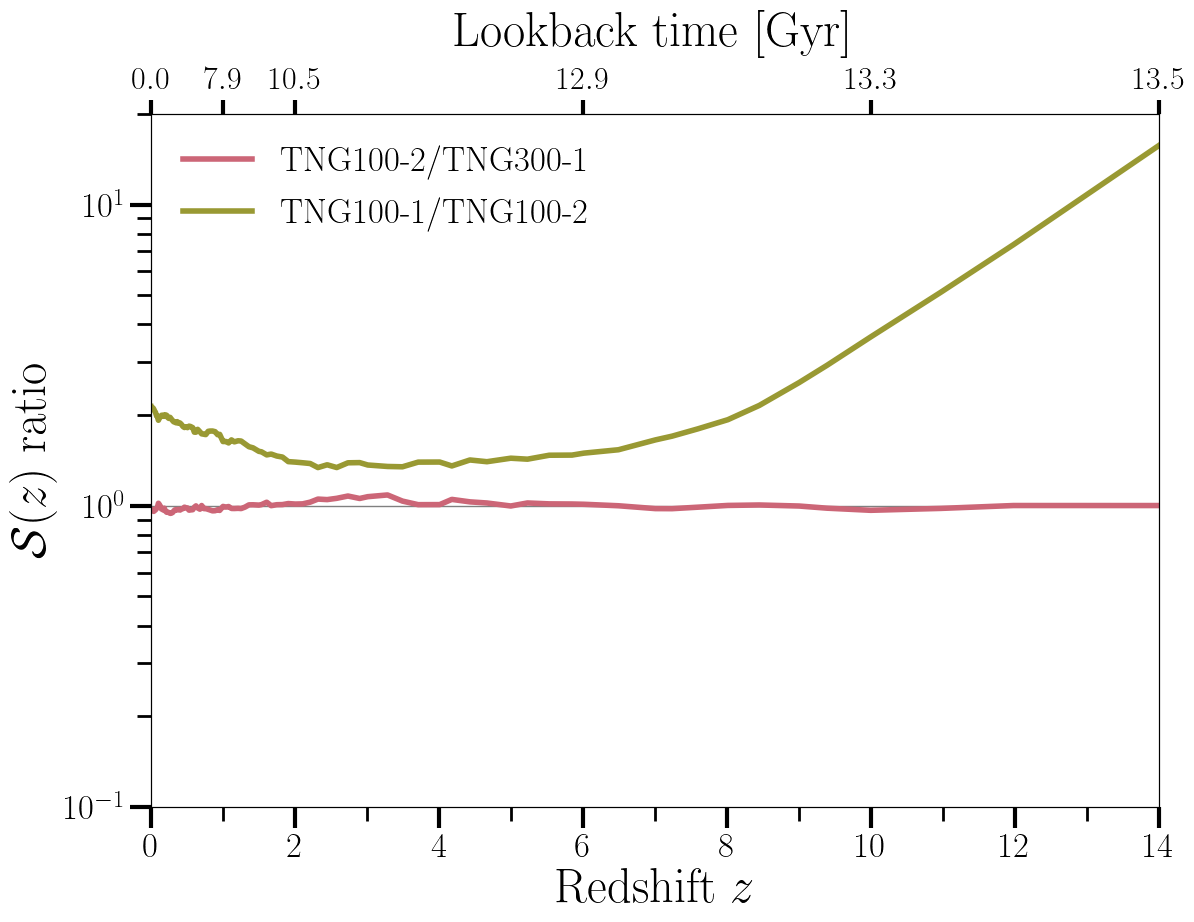

In [72]:
#S(z) ratios control set

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
ax.axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25) 
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_ylabel(r'$\mathcal{S}(z)$ ratio', fontsize = 35)
ax.set_xlabel(r"Redshift $z$", fontsize = 35)
ax.set_yscale('log')

#set up second x axis
ax2 = ax.twiny()
redshift_tick_list = [0, 1, 2, 6, 10, 14]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')

#Set limits for horizontal axis
ax.set_xlim(0, 14)
ax2.set_xlim(0, 14) 
ax.set_ylim(1e-1, 2e1)


ax.plot(Redshifts[0], S_z[4]/S_z[5], lw=4, c=data_colors_all[0], label='%s/%s'%(tngs[4], tngs[5]))
ax.plot(Redshifts[0], S_z[3]/S_z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]))
#ax.plot(Redshifts[0], S_z[1]/S_z[3], lw=4, c=data_colors_all[2], label='%s/%s'%(tngs[1], tngs[3]))
#ax.plot(Redshifts[0], S_z[2]/S_z[5], lw=4, c=data_colors_all[3], label='%s/%s'%(tngs[2], tngs[5]))

print(np.amax((S_z[4][3:-10]-S_z[5][3:-10])/S_z[5][3:-10]) *100, '%')
print(np.amax((S_z[3][3:-10]-S_z[4][3:-10])/S_z[4][3:-10]) *100, '%')
#print(np.amax((S_z[4][3:-10]-S_z[5][3:-10])/S_z[5][3:-10]) *100, '%')
#print(np.amax((S_z[3][3:-10]-S_z[4][3:-10])/S_z[4][3:-10]) *100, '%')


ax.legend(fontsize = 25, frameon=False)
#fig.savefig('figures/compareSFR_control.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/799830330.py:30: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Redshifts[0], (S_z[3]-S_z[4])/S_z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)


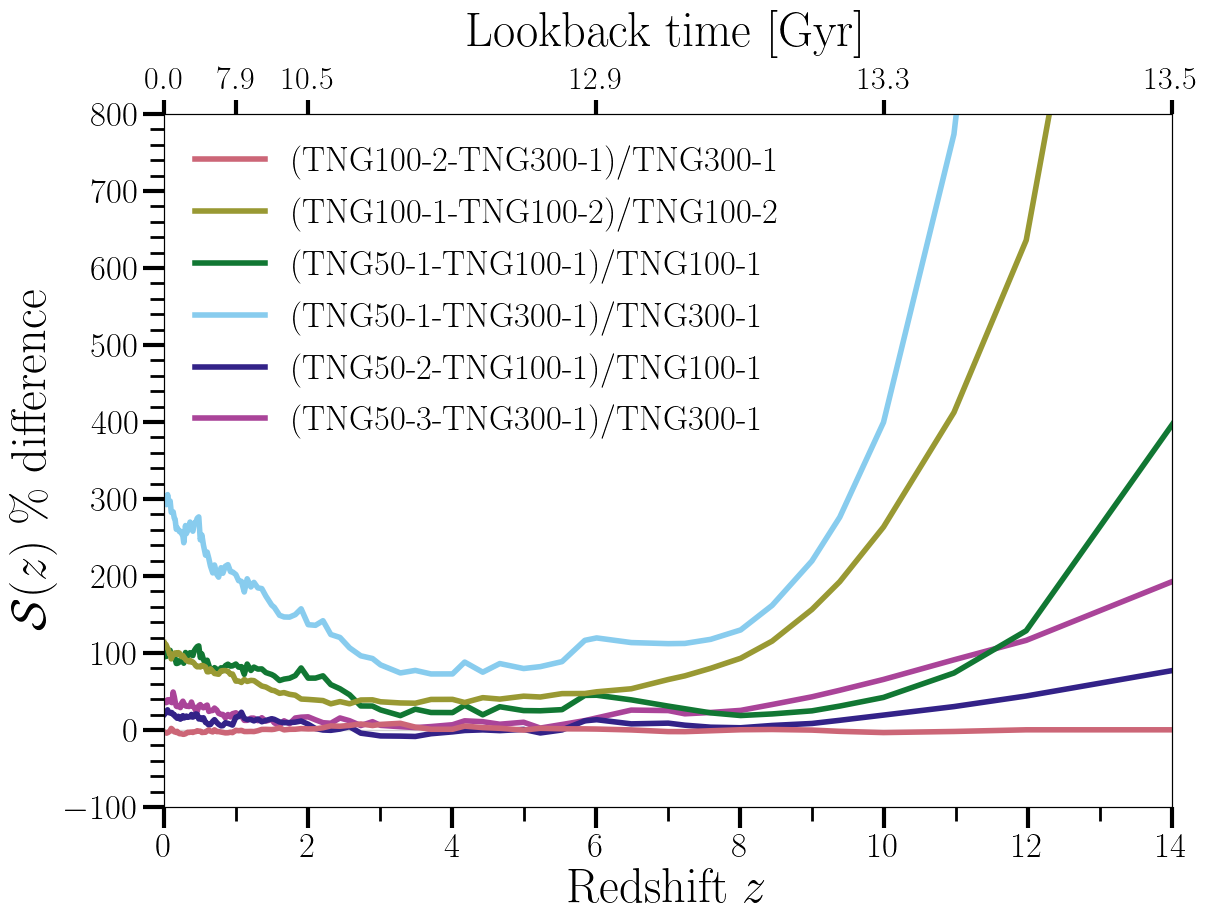

In [73]:
#S(z) percent difference

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
ax.axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(20))
ax.set_xlabel(r"Redshift $z$", fontsize = 35)
ax.set_ylabel(r'$\mathcal{S}(z)$ \% difference', fontsize = 35)

#Set limits for horizontal axis
ax.set_xlim(0, 14)
ax.set_ylim(-100, 800)

#set up second x axis
ax2 = ax.twiny()
redshift_tick_list = [0, 1, 2, 6, 10, 14]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')
ax2.set_xlim(0, 14) 

ax.plot(Redshifts[0], (S_z[4]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[0], label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]), zorder=6)
ax.plot(Redshifts[0], (S_z[3]-S_z[4])/S_z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)
ax.plot(Redshifts[0], (S_z[0]-S_z[3])/S_z[3]*100, lw=4, c=data_colors_all[2], label='(%s-%s)/%s'%(tngs[0], tngs[3], tngs[3]), zorder=4)
ax.plot(Redshifts[0], (S_z[0]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[3], label='(%s-%s)/%s'%(tngs[0], tngs[5], tngs[5]), zorder=3)
ax.plot(Redshifts[0], (S_z[1]-S_z[3])/S_z[3]*100, lw=4, c=data_colors_all[4], label='(%s-%s)/%s'%(tngs[1], tngs[3], tngs[3]), zorder=2)
ax.plot(Redshifts[0], (S_z[2]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[5], label='(%s-%s)/%s'%(tngs[2], tngs[5], tngs[5]), zorder=1)

ax.legend(fontsize = 25, frameon=False)
fig.savefig('figures/compareSFR_percent.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1898452479.py:29: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Redshifts[0], (S_z[3]-S_z[4])/S_z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]))


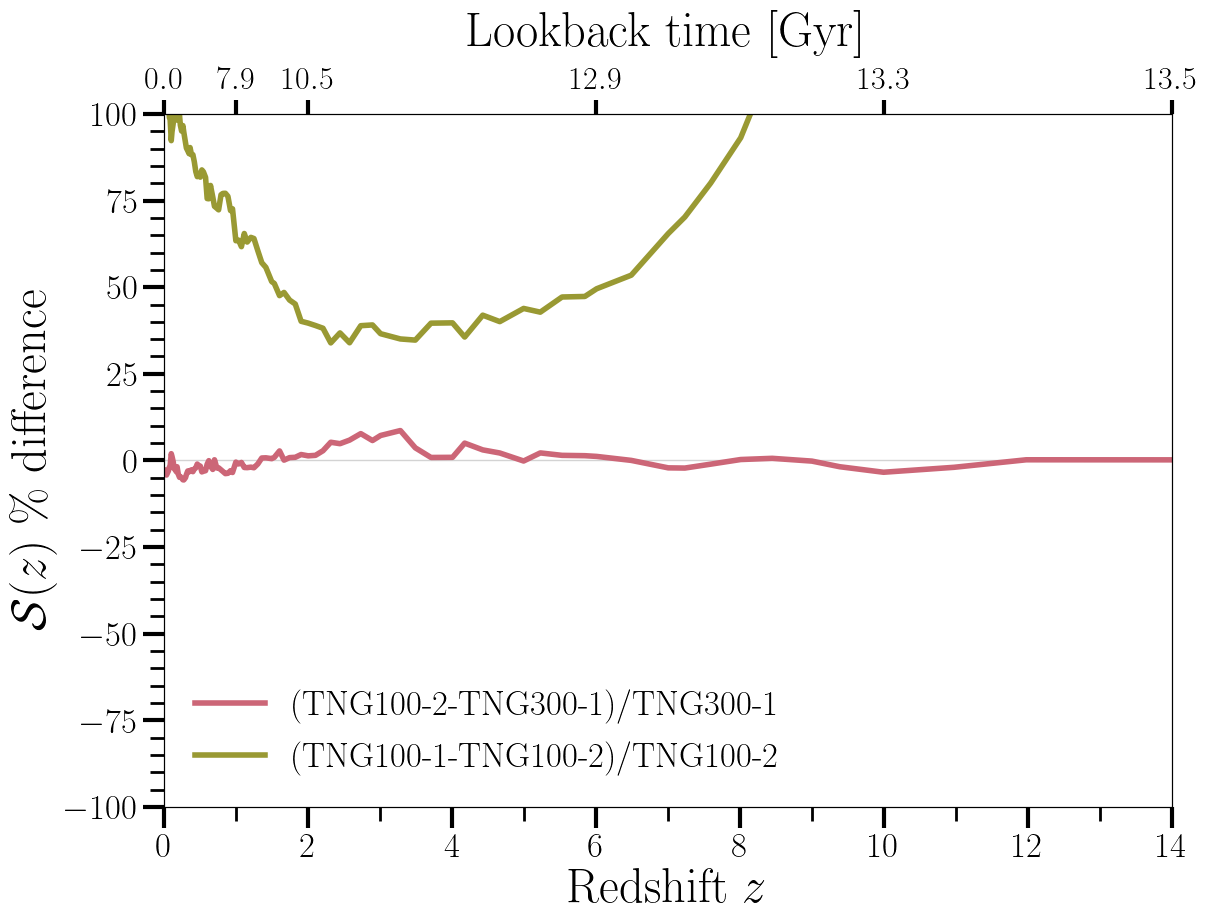

In [74]:
#S(z) percent difference control

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
ax.axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.set_xlabel(r"Redshift $z$", fontsize = 35)
ax.set_ylabel(r'$\mathcal{S}(z)$ \% difference', fontsize = 35)

#Set limits for horizontal axis
ax.set_xlim(0, 14)
ax.set_ylim(-100, 100)

ax2 = ax.twiny()
redshift_tick_list = [0, 1, 2, 6, 10, 14]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')
ax2.set_xlim(0, 14) 

ax.plot(Redshifts[0], (S_z[4]-S_z[5])/S_z[5]*100, lw=4, c=data_colors_all[0], label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]))
ax.plot(Redshifts[0], (S_z[3]-S_z[4])/S_z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]))

ax.legend(fontsize = 25, frameon=False)
#fig.savefig('figures/compareSFR_percent_control.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1024664449.py:23: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[4]/S_Z[5], lw=4, c=data_colors_all[0], label='%s/%s'%(tngs[4], tngs[5]), zorder=6)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1024664449.py:24: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]), zorder=5)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1024664449.py:24: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]), zorder=5)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1024664449.py:25: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[0]/S_Z[3], lw=4, c=data_colors_all[2], label='%s/%s'%(tngs[0], tngs[3]), zorder=4)
/var/folde

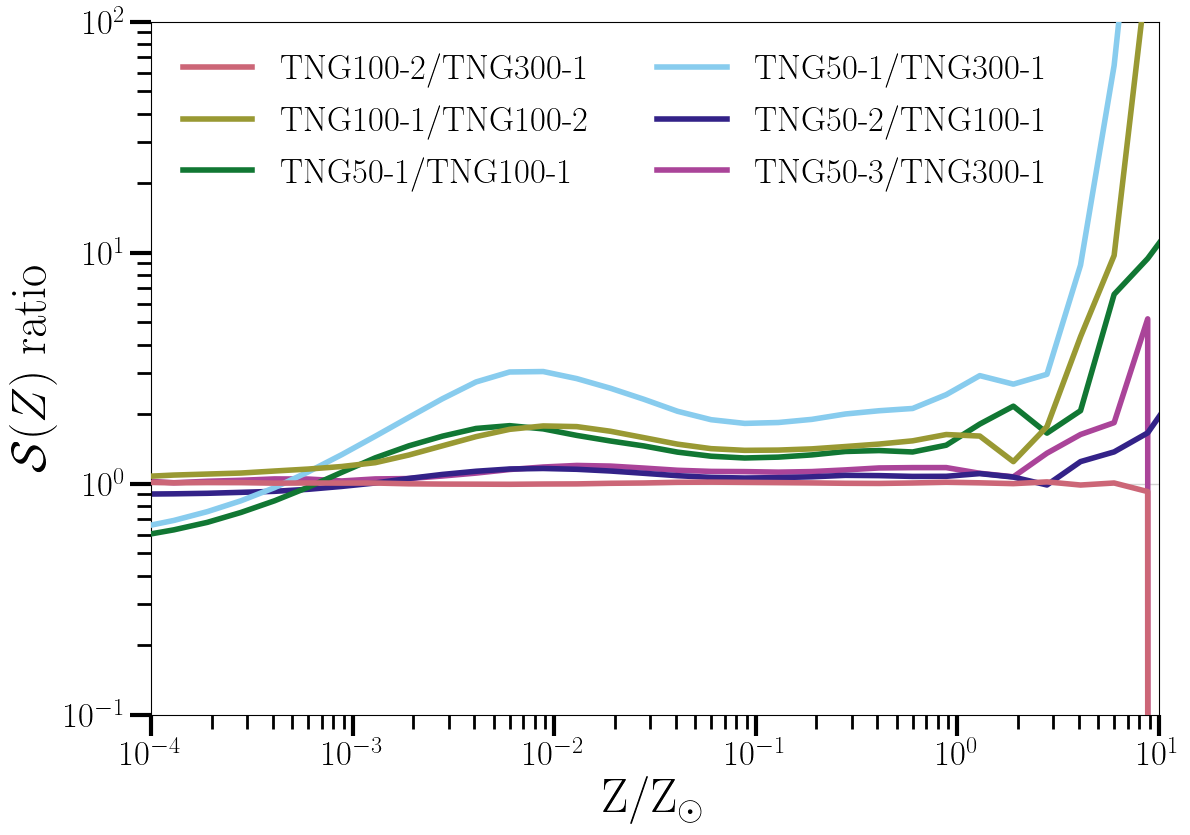

In [75]:
#S(Z) ratios 

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
Zsun = 0.014
ax.axhline(y=1, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_xlabel(r"Z/Z$_\odot$", fontsize = 35)
ax.set_ylabel(r'$\mathcal{S}(Z)$ ratio', fontsize = 35)

ax.set_xscale('log')
ax.set_yscale('log')

#Set limits for horizontal axis
ax.set_xlim(10**-4, 10)
ax.set_ylim(1e-1, 1e2)

ax.plot(Zbins[0]/Zsun, S_Z[4]/S_Z[5], lw=4, c=data_colors_all[0], label='%s/%s'%(tngs[4], tngs[5]), zorder=6)
ax.plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]), zorder=5)
ax.plot(Zbins[0]/Zsun, S_Z[0]/S_Z[3], lw=4, c=data_colors_all[2], label='%s/%s'%(tngs[0], tngs[3]), zorder=4)
ax.plot(Zbins[0]/Zsun, S_Z[0]/S_Z[5], lw=4, c=data_colors_all[3], label='%s/%s'%(tngs[0], tngs[5]), zorder=3)
ax.plot(Zbins[0]/Zsun, S_Z[1]/S_Z[3], lw=4, c=data_colors_all[4], label='%s/%s'%(tngs[1], tngs[3]), zorder=2)
ax.plot(Zbins[0]/Zsun, S_Z[2]/S_Z[5], lw=4, c=data_colors_all[5], label='%s/%s'%(tngs[2], tngs[5]), zorder=1)

ax.legend(fontsize = 25, frameon=False, ncol=2)
fig.savefig('figures/compareZ_dist_allTNGs.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

1.7787425887805297 %
77.7555683941192 %


/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/4208387581.py:23: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[4]/S_Z[5], lw=4, c=data_colors_all[0], label='%s/%s'%(tngs[4], tngs[5]))
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/4208387581.py:24: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]))
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/4208387581.py:24: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]))


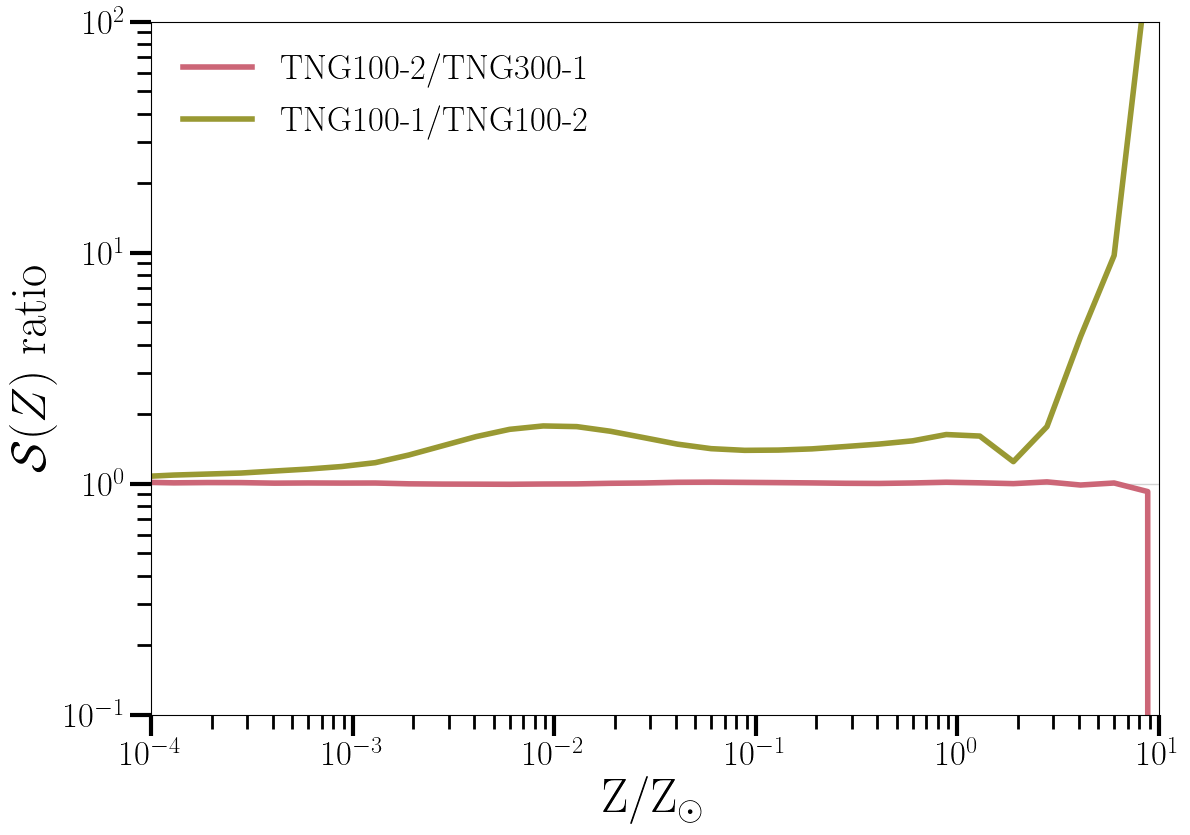

In [76]:
#S(Z) ratios for control set

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
Zsun = 0.014
ax.axhline(y=1, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_xlabel(r"Z/Z$_\odot$", fontsize = 35)
ax.set_ylabel(r'$\mathcal{S}(Z)$ ratio', fontsize = 35)

ax.set_xscale('log')
ax.set_yscale('log')

#Set limits for horizontal axis
ax.set_xlim(10**-4, 10)
ax.set_ylim(1e-1, 1e2)

ax.plot(Zbins[0]/Zsun, S_Z[4]/S_Z[5], lw=4, c=data_colors_all[0], label='%s/%s'%(tngs[4], tngs[5]))
ax.plot(Zbins[0]/Zsun, S_Z[3]/S_Z[4], lw=4, c=data_colors_all[1], label='%s/%s'%(tngs[3], tngs[4]))
#ax.plot(Zbins[0]/Zsun, S_Z[1]/S_Z[3], lw=4, c=data_colors_all[2], label='%s/%s'%(tngs[1], tngs[3]))
#ax.plot(Zbins[0]/Zsun, S_Z[2]/S_Z[4], lw=4, c=data_colors_all[3], label='%s/%s'%(tngs[2], tngs[5]))
print(np.amax((S_Z[4][5:-5]-S_Z[5][5:-5])/S_Z[5][5:-5]) *100, '%')
print(np.amax((S_Z[3][5:-8]-S_Z[4][5:-8])/S_Z[4][5:-8]) *100, '%')
#print(np.amax((S_Z[1][5:-5]-S_Z[3][5:-5])/S_Z[5][5:-5]) *100, '%')
#print(np.amax((S_Z[2][5:-8]-S_Z[5][5:-8])/S_Z[5][5:-8]) *100, '%')


ax.legend(fontsize = 25, frameon=False)
#fig.savefig('figures/compareZ_dist_control.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/872544173.py:25: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[4]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[0], label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]), zorder=6)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/872544173.py:26: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/872544173.py:26: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/872544173.py:27: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[0]-S_Z[3])/S_Z[

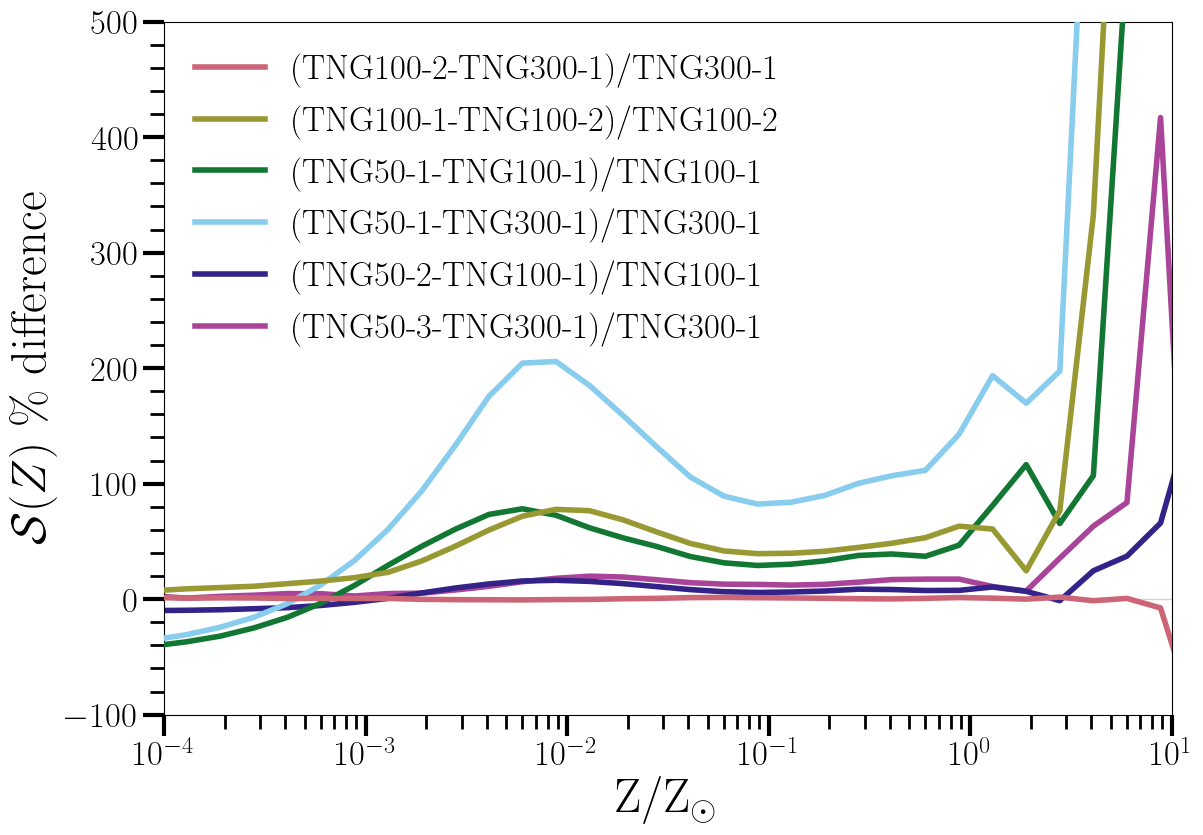

In [77]:
#S(Z) percent difference

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
Zsun = 0.014
ax.axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(20))
ax.set_xlabel(r"Z/Z$_\odot$", fontsize = 35)
ax.set_ylabel(r'$\mathcal{S}(Z)$ \% difference', fontsize = 35)

ax.set_xscale('log')
#ax.set_yscale('log')

#Set limits for horizontal axis
ax.set_xlim(10**-4, 10)
ax.set_ylim(-100, 500)



ax.plot(Zbins[0]/Zsun, (S_Z[4]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[0], label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]), zorder=6)
ax.plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]), zorder=5)
ax.plot(Zbins[0]/Zsun, (S_Z[0]-S_Z[3])/S_Z[3]*100, lw=4, c=data_colors_all[2], label='(%s-%s)/%s'%(tngs[0], tngs[3], tngs[3]), zorder=4)
ax.plot(Zbins[0]/Zsun, (S_Z[0]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[3], label='(%s-%s)/%s'%(tngs[0], tngs[5], tngs[5]), zorder=3)
ax.plot(Zbins[0]/Zsun, (S_Z[1]-S_Z[3])/S_Z[3]*100, lw=4, c=data_colors_all[4], label='(%s-%s)/%s'%(tngs[1], tngs[3], tngs[3]), zorder=2)
ax.plot(Zbins[0]/Zsun, (S_Z[2]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[5], label='(%s-%s)/%s'%(tngs[2], tngs[5], tngs[5]), zorder=1)

ax.legend(fontsize = 25, frameon=False)
fig.savefig('figures/compareZ_dist_percent.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1003600461.py:23: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[4]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[0], label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]))
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1003600461.py:24: RuntimeWarning: divide by zero encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]))
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1003600461.py:24: RuntimeWarning: invalid value encountered in divide
  ax.plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]))


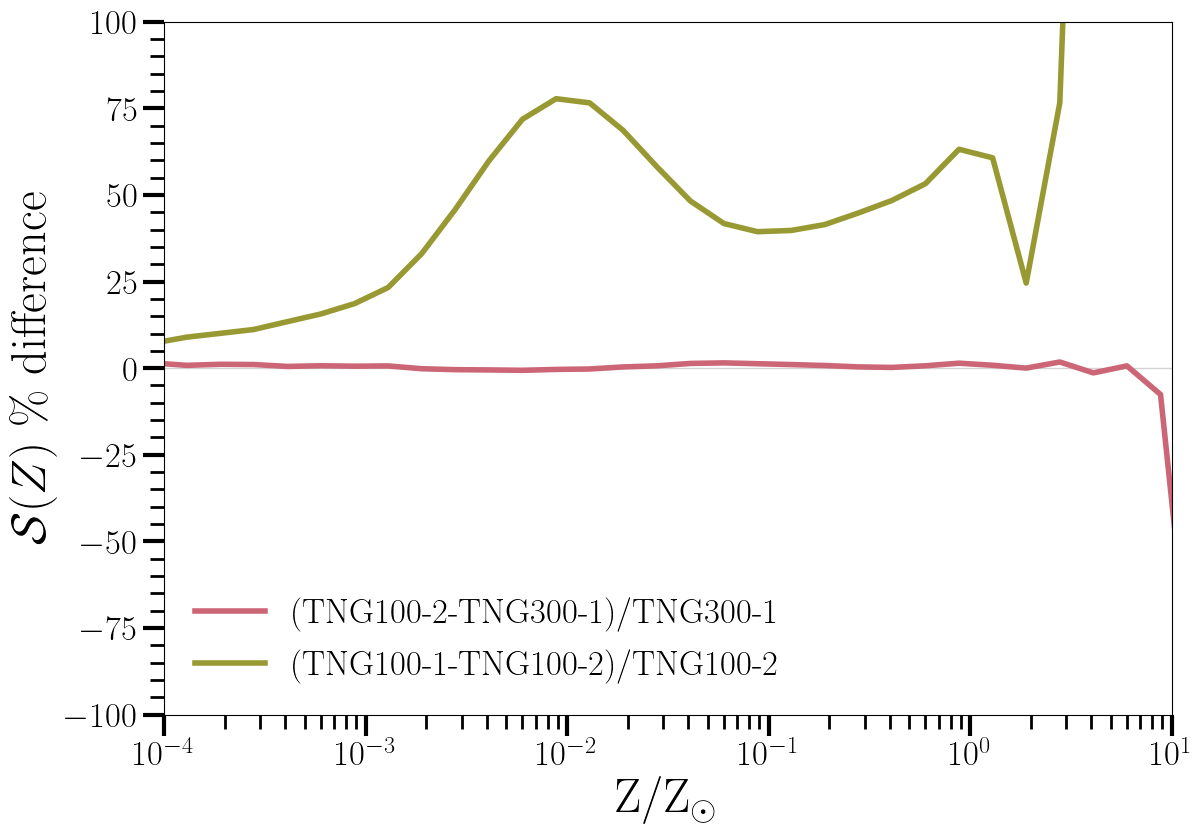

In [78]:
#S(Z) percent difference

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
Zsun = 0.014
ax.axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.set_xlabel(r"Z/Z$_\odot$", fontsize = 35)
ax.set_ylabel(r'$\mathcal{S}(Z)$ \% difference', fontsize = 35)

ax.set_xscale('log')
#ax.set_yscale('log')

#Set limits for horizontal axis
ax.set_xlim(10**-4, 10)
ax.set_ylim(-100, 100)

ax.plot(Zbins[0]/Zsun, (S_Z[4]-S_Z[5])/S_Z[5]*100, lw=4, c=data_colors_all[0], label='(%s-%s)/%s'%(tngs[4], tngs[5], tngs[5]))
ax.plot(Zbins[0]/Zsun, (S_Z[3]-S_Z[4])/S_Z[4]*100, lw=4, c=data_colors_all[1], label='(%s-%s)/%s'%(tngs[3], tngs[4], tngs[4]))

ax.legend(fontsize = 25, frameon=False)
#fig.savefig('figures/compareZ_dist_percent_control.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

## Normalized S(z) and S(Z) plots

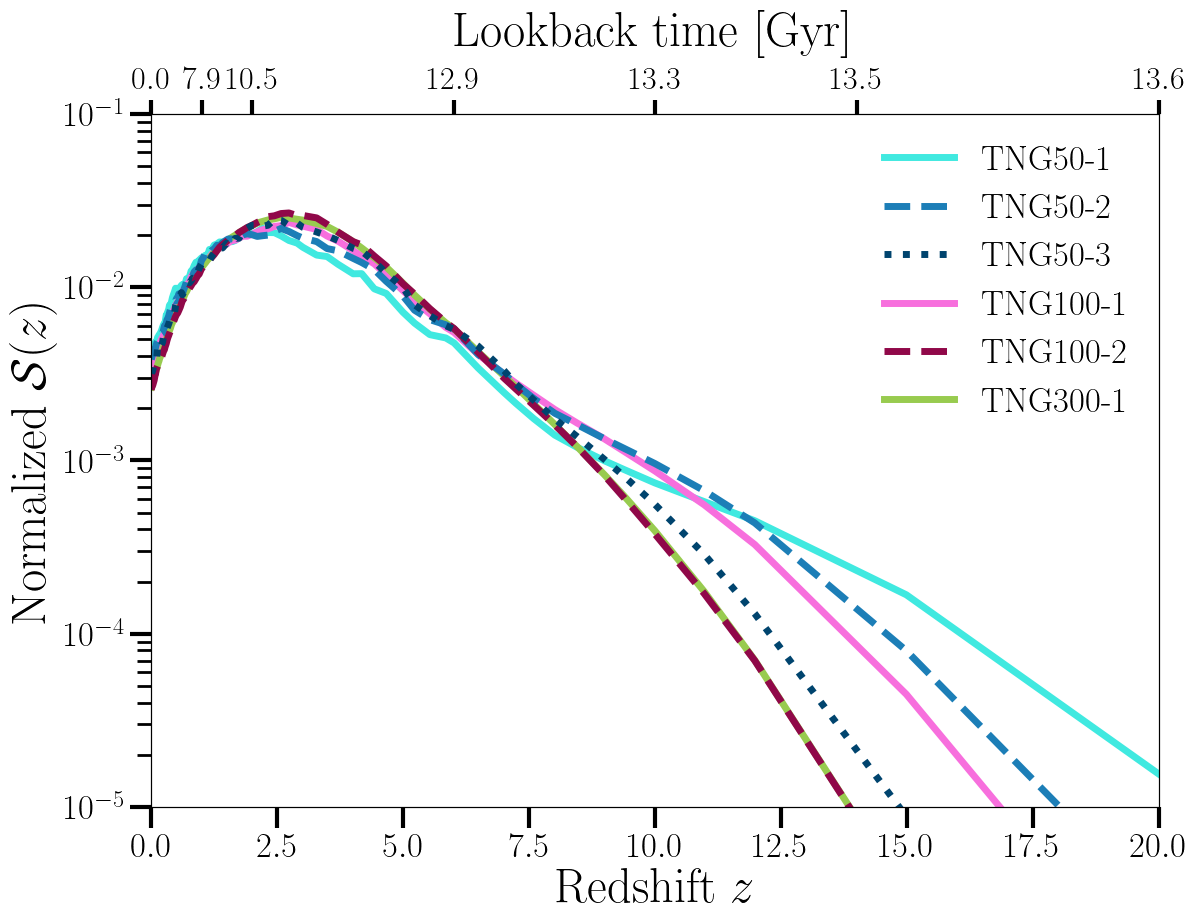

In [79]:
#Normalized S(z)

fig, ax = plt.subplots(figsize=(13, 9))
tngs = ['TNG50-1', 'TNG50-2', 'TNG50-3', 'TNG100-1', 'TNG100-2', 'TNG300-1'] 
data_colors_tng = ['#40E9E0', '#1C7EB7', "#00446E",'#F76FDD', "#900849", '#98CB4F', "#589019", 'black', 'gray', 'lightgray']

#Plot setup
ax.axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1
ax.tick_params(axis='both', which='major', labelsize=25) 
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
#ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_ylabel(r'Normalized $\mathcal{S}(z)$', fontsize = 35)
ax.set_xlabel(r"Redshift $z$", fontsize = 35)
ax.set_yscale('log')

#set up second x axis
ax2 = ax.twiny()
redshift_tick_list = [0, 1, 2, 6, 10, 14, 20]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')

#Set limits for horizontal axis
ax.set_xlim(0, 20)
ax2.set_xlim(0, 20) 
ax.set_ylim(10**-5, 10**-1)

# ax.plot(Redshifts[0], Z_SFRD.Madau_Dickinson2014(Sim_Redshifts, a=0.01, b=2.6, c=3.2, d=6.2)/np.sum(Z_SFRD.Madau_Dickinson2014(Sim_Redshifts, a=0.01, b=2.6, c=3.2, d=6.2)), 
#             label = r'M\&F 2017', #+'\n'+'$a=%.2f, b=%.2f, c=%.2f, d=%.2f$'% (0.01,2.6,3.2,6.2), 
#             c = 'gray',lw=3, zorder=0)

for i, tng in enumerate(tngs):

    if vers[i]==1:
        linestyle='-'
        z_order=1
    if vers[i]==2:
        linestyle='--'
        z_order=2
    if vers[i]==3:
        linestyle=':'
        z_order=3

    ax.plot(Redshifts[i], S_z[i]/np.sum(S_z[i]), lw=5, ls=linestyle, c=data_colors_tng[i], label=tng, zorder=z_order)

ax.legend(fontsize = 25, frameon=False)
fig.savefig('figures/normalizedSFR_allTNGs.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

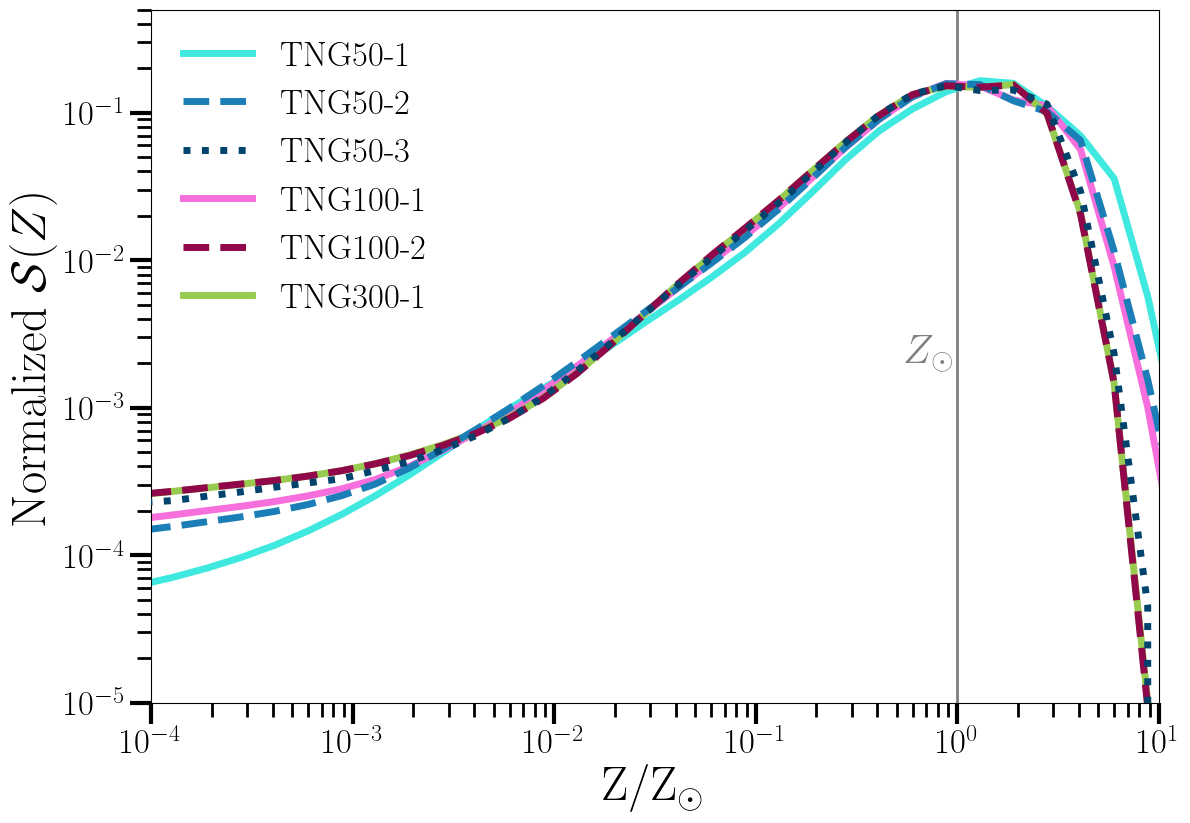

In [80]:
#Normalized S(Z)

fig, ax = plt.subplots(figsize=(13, 9))

#Plot setup
Zsun = 0.014
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_xlabel(r"Z/Z$_\odot$", fontsize = 35)
ax.set_ylabel(r'Normalized $\mathcal{S}(Z)$', fontsize = 35)

ax.set_xscale('log')
ax.set_yscale('log')

#Set limits for horizontal axis
ax.set_xlim(10**-4, 10)
ax.set_ylim(1e-5, 0.5)

ax.axvline(x=1, linewidth=2, color='gray', zorder=0)
ax.text(x=0.55, y= 0.002, s='$Z_\odot$', fontsize=30, color='gray')

for i, tng in enumerate(tngs):

    if vers[i]==1:
        linestyle='-'
        z_order=1
    if vers[i]==2:
        linestyle='--'
        z_order=2
    if vers[i]==3:
        linestyle=':'
        z_order=3

    ax.plot(Zbins[i]/Zsun, S_Z[i]/np.sum(S_Z[i]), lw=5, ls=linestyle, zorder=z_order, c=data_colors_tng[i], label=tng)

ax.legend(fontsize = 25, frameon=False)
fig.savefig('figures/normalizedZ_dist_allTNGs.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

## S(Z,z) plots

In [17]:
from SFRD_2Dplots import SFRDplot_2D
import get_ZdepSFRD as Z_SFRD
import paths

tngs=['TNG50-1', 'TNG100-1', 'TNG100-2', 'TNG300-1'] 
vers = [1, 1, 2, 1]
rbox = [35, 75, 75, 205]

In [18]:
#Read the TNG data and interpolate it
SFRDsTNG= []
redshiftsTNG = []
LookbacktimesTNG = []
metalsTNG = []
step_fit_logZ_TNG = []

for n, tng in enumerate(tngs):
    Cosmol_sim_location = paths.data / str("SFRMetallicityFromGasWithMetals%s.hdf5"%(tng))
    Sim_SFRD, Lookbacktimes, Redshifts, Sim_center_Zbin, step_fit_logZ = readTNGdata(tng, loc = Cosmol_sim_location, rbox=rbox[n], SFR=False, metals=False)
    #SFRDnew, redshift_new, Lookbacktimes_new, metals_new, step_fit_logZ_new = interpolate_TNGdata(Redshifts, Lookbacktimes, Sim_SFRD, Sim_center_Zbin, tng, vers[n], redshiftlimandstep=[0, 20, 0.05], Nmetals=500, saveplot=False)
    SFRDnew, redshift_new, Lookbacktimes_new, metals_new, step_fit_logZ_new = Sim_SFRD.T, Redshifts, Lookbacktimes, Sim_center_Zbin, step_fit_logZ
    SFRDsTNG.append(SFRDnew)
    redshiftsTNG.append(redshift_new)
    LookbacktimesTNG.append(Lookbacktimes_new)
    metalsTNG.append(metals_new)
    step_fit_logZ_TNG.append(step_fit_logZ_new)

numerator = [SFRDsTNG[2], SFRDsTNG[1], SFRDsTNG[0], SFRDsTNG[0]]
denominator = [SFRDsTNG[3], SFRDsTNG[2], SFRDsTNG[1], SFRDsTNG[3]]
tnglabels = ['%s/%s'%(tngs[2],tngs[3]), '%s/%s'%(tngs[1],tngs[2]), '%s/%s'%(tngs[0],tngs[1]), '%s/%s'%(tngs[0],tngs[3])]

[Text(0, 0.0001, '$\\mathdefault{10^{-4}}$'), Text(0, 0.001, '$\\mathdefault{10^{-3}}$'), Text(0, 0.01, '$\\mathdefault{10^{-2}}$'), Text(0, 0.1, '$\\mathdefault{10^{-1}}$'), Text(0, 1.0, '$\\mathdefault{10^{0}}$'), Text(0, 10.0, '$\\mathdefault{10^{1}}$'), Text(0, 100.0, '$\\mathdefault{10^{2}}$')]
[1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02]


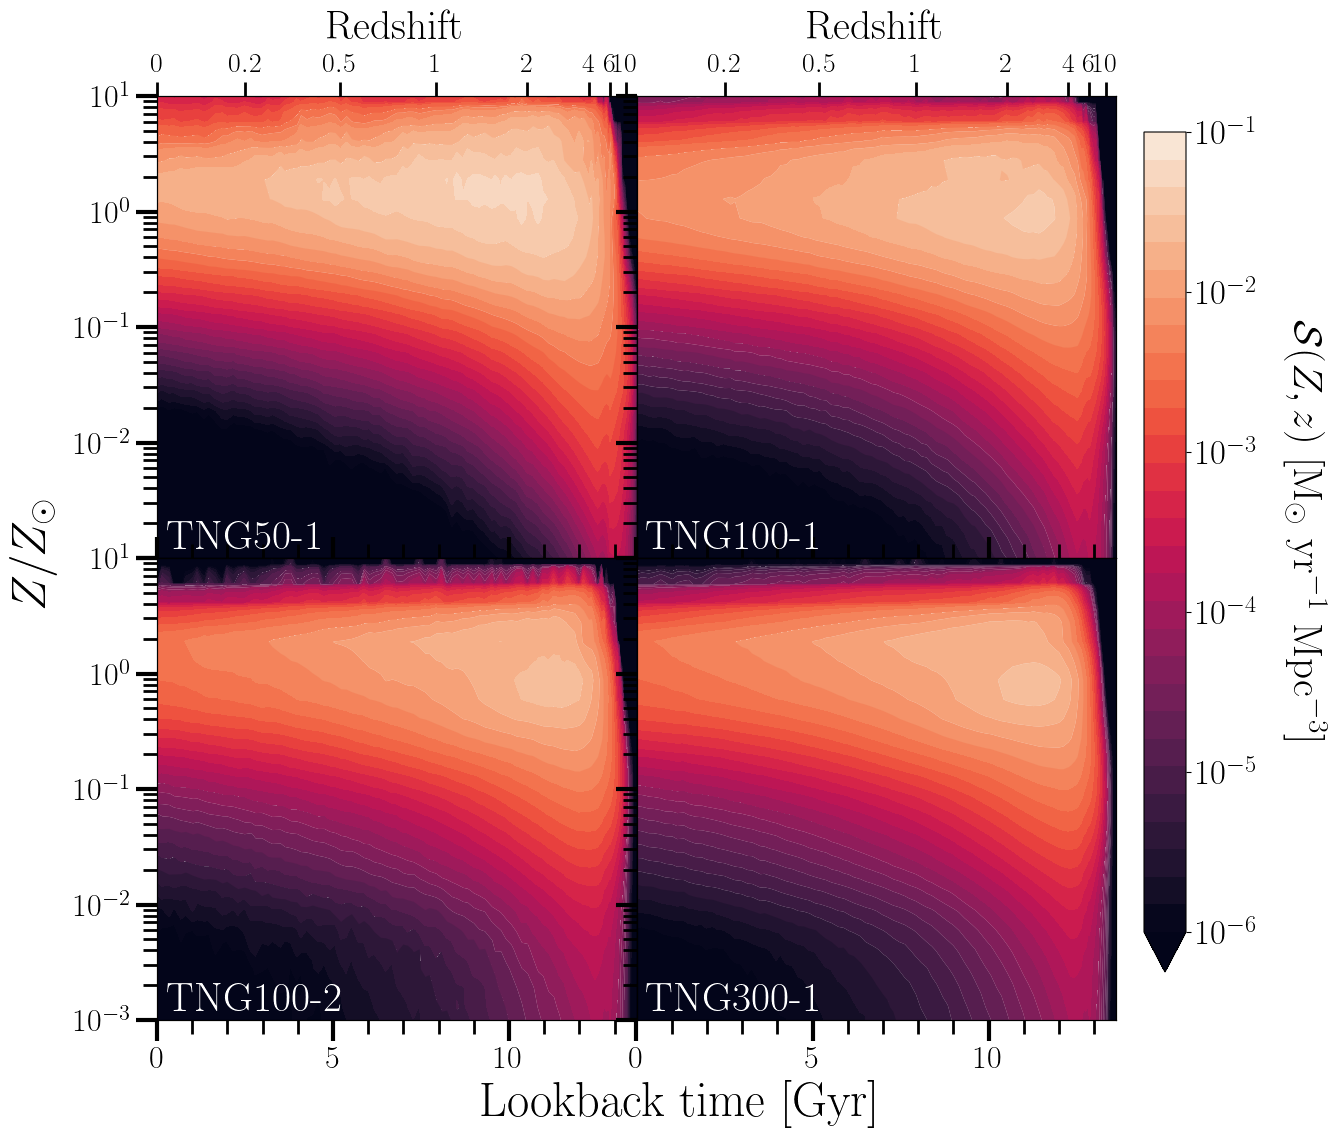

In [19]:
SFRDplot_2D(metalsTNG, LookbacktimesTNG, SFRDsTNG, tngs, vers, ylim=[10**-3, 10], nlevels=30, model=[], plottype='data', plotredshift=False)

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/781462081.py:11: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax = plt.subplot(ceil(len(tngs)/2), 2, n + 1)


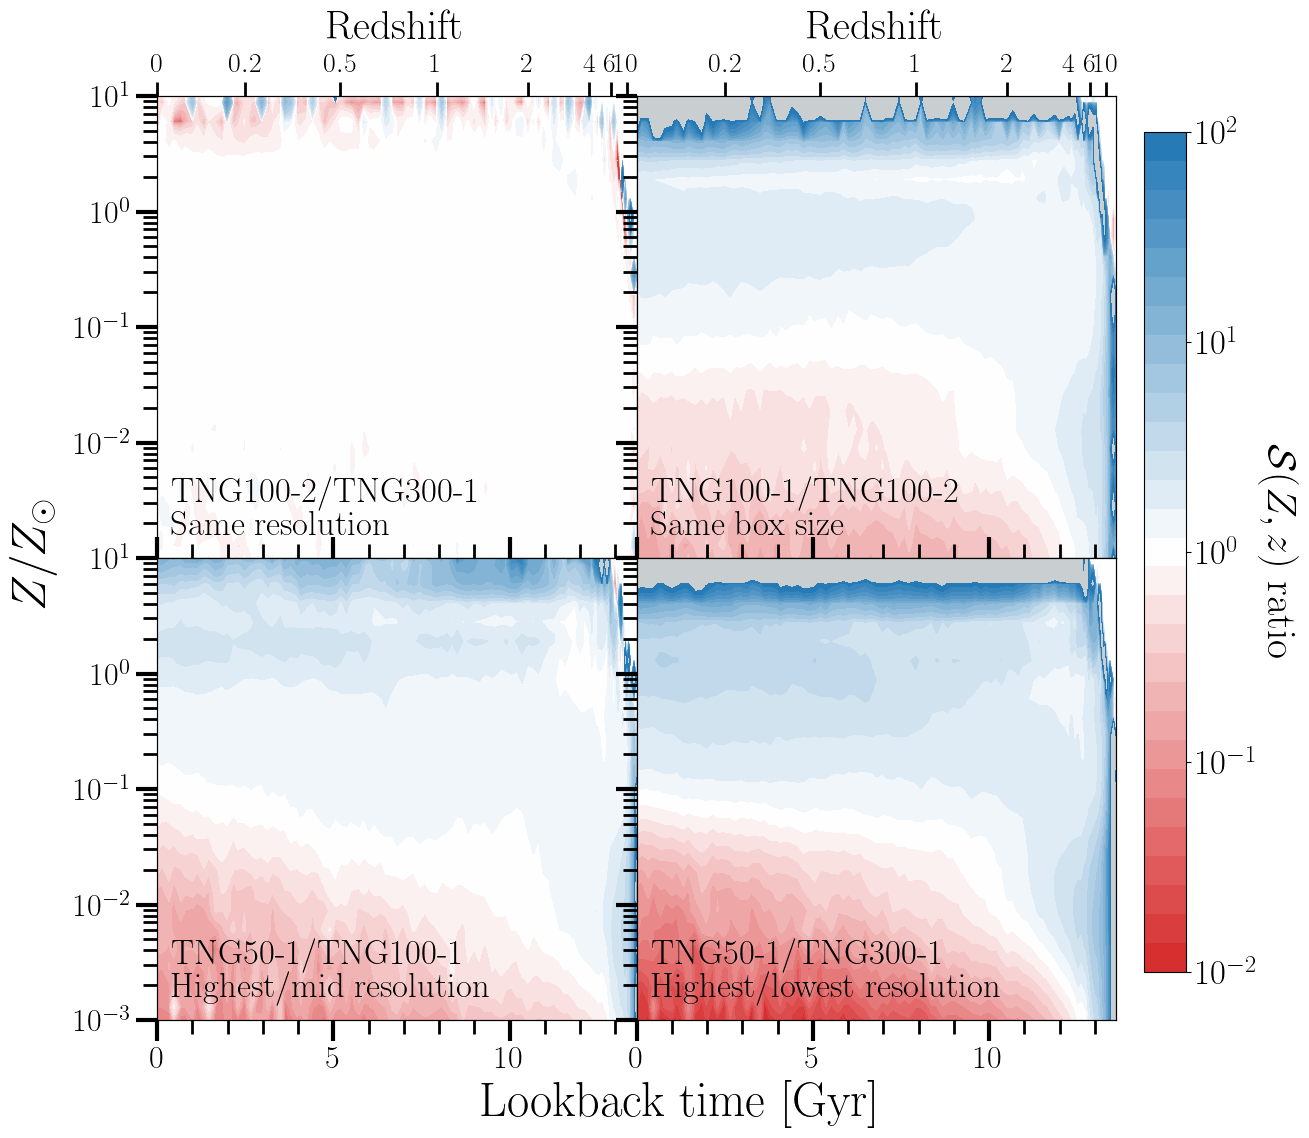

In [20]:
Zsun = 0.014 #Solar metallicity
cmap = matplotlib.colors.LinearSegmentedColormap.from_list('', ['tab:red', 'white', 'tab:blue'])
#cmap = sns.color_palette('rocket', as_cmap=True)

fig, ax = plt.subplots(figsize = (14,12))
fig.subplots_adjust(wspace=0, hspace=0)
tnglabels = ['%s/%s'%(tngs[2],tngs[3]), '%s/%s'%(tngs[1],tngs[2]), '%s/%s'%(tngs[0],tngs[1]), '%s/%s'%(tngs[0],tngs[3])]
tnglabels2 = ['Same resolution', 'Same box size', 'Highest/mid resolution', 'Highest/lowest resolution']

for n, tng in enumerate(numerator):
    ax = plt.subplot(ceil(len(tngs)/2), 2, n + 1)

    #Plot data and is model is given plot model

    #numerator[n][numerator[n] < 1e-7] = 1e-7
    #denominator[n][denominator[n] < 1e-7] = 1e-7
    percenterr = numerator[n]/denominator[n]
    levels = np.logspace(-2,2, 30) #np.linspace(0, 100, 30)
    data = ax.contourf(LookbacktimesTNG[n], metalsTNG[n]/Zsun, percenterr, levels=levels, cmap=cmap, norm=matplotlib.colors.LogNorm(vmin=1e-2, vmax=1e2))
    ax.set_facecolor("#c9ced1")

    ax.text(0.03, 0.12, tnglabels[n], transform=ax.transAxes, fontsize=25, color='black')
    ax.text(0.03, 0.05, tnglabels2[n], transform=ax.transAxes, fontsize=25, color='black')

    #Set yscale, TNG version label on each plot, and axis labels
    ax.set_yscale('log')
    fig.supxlabel('Lookback time [Gyr]', y=0.02, fontsize=35)
    fig.supylabel(r'$Z/Z_{\rm{\odot}}$', x=0.02, fontsize=35)
    ax.tick_params(axis='both', which='major', labelsize=23)
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.tick_params(length=15, width=3, which='major')
    ax.tick_params(length=10, width=2, which='minor')

    #Set redshift ticks; make sure they don't overlap
    ax2 = ax.twiny()
    if n==1:
        redshift_tick_list = [0.2, 0.5, 1.0, 2, 4, 6, 10]
    else:
        redshift_tick_list = [0, 0.2, 0.5, 1.0, 2, 4, 6, 10]
    
    # #Hide overlapping tick labels
    if n==0:
        ax.set_yticks([1e-2, 1e-1, 1e0, 1e1])
        ax.set_yticklabels(['$\\mathdefault{10^{-2}}$', '$\\mathdefault{10^{-1}}$', '$\\mathdefault{10^{0}}$', '$\\mathdefault{10^{1}}$'])

    #Hide tick labels depending on how many subplots are in the figure, and their configuration
    if n%2==0:
        if len(tngs) > 2 and n<len(tngs)-2: #if left column with more than two subplots, but not last row, hide ticks and labels
            ax.tick_params(axis='x',  which='both', labelbottom=False, direction='in')
    else:
        if len(tngs) ==2: #if right subplot with only one row, hide left ticks on the left side
            ax.tick_params(axis='both',  which='both', labelleft=False)
        elif len(tngs) > 2 and n<len(tngs)-2: #if right subplot with more than one row, hide left and bottom ticks
            ax.tick_params(axis='y',  which='both', labelleft=False)
            ax.tick_params(axis='x',  which='both', labelbottom=False, direction='in')
        else: #if last right subplot, hide left label
            ax.tick_params(axis='both',  which='both', labelleft=False)

    #Set redshift axis labels for only first row of subplots
    if n < 2: 
        ax2.set_xlabel('Redshift', fontsize = 30, labelpad=10)
        ax2.set_xticks([cosmo.lookback_time(z).value for z in redshift_tick_list])
        ax2.set_xticklabels(['${:g}$'.format(z) for z in redshift_tick_list])
    else:
        ax2.set_xlabel('', fontsize = 30)
        ax2.set_xticks([cosmo.lookback_time(z).value for z in redshift_tick_list*0])
        ax2.set_xticklabels(['${:g}$'.format(z) for z in redshift_tick_list*0])

    ax2.tick_params(axis='both', which='major', labelsize=20)
    ax2.tick_params(length=10, width=2, which='major')

    #Set limits for horizontal (lookback time) and vertical (metallicity) axes
    ax.set_xlim(0, 13.6) #not always want to set xlimits, so empty if not using any; in lookback time
    ax2.set_xlim(0, 13.6) #in lookback time
    ax.set_ylim(10**-3, 10) #defaults for TNG data are Z=10**-1 to Z=10**1

#Set up the colorbar
fig.subplots_adjust(right=0.81)
cbar_ax = fig.add_axes([0.83, 0.15, 0.03, 0.7])
#ticks = np.arange(0.1, 10, 1)
cbar = fig.colorbar(data, cax=cbar_ax, ticks=[1e-2, 1e-1, 1e0, 1e1, 1e2])
cbar.ax.tick_params(labelsize=25)

cbar.set_label(r'$\mathcal{S}(Z,z)$ ratio', rotation=270, fontsize=30, labelpad=30);
fig.savefig('figures/SFRD_Z_z_difference.pdf', bbox_inches='tight')

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/4238832519.py:12: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax = plt.subplot(ceil(len(tngs)/2), 2, n + 1)


Axes(0.125,0.495;0.3875x0.385)
Axes(0.5125,0.495;0.3875x0.385)
Axes(0.125,0.11;0.3875x0.385)
Axes(0.5125,0.11;0.3875x0.385)


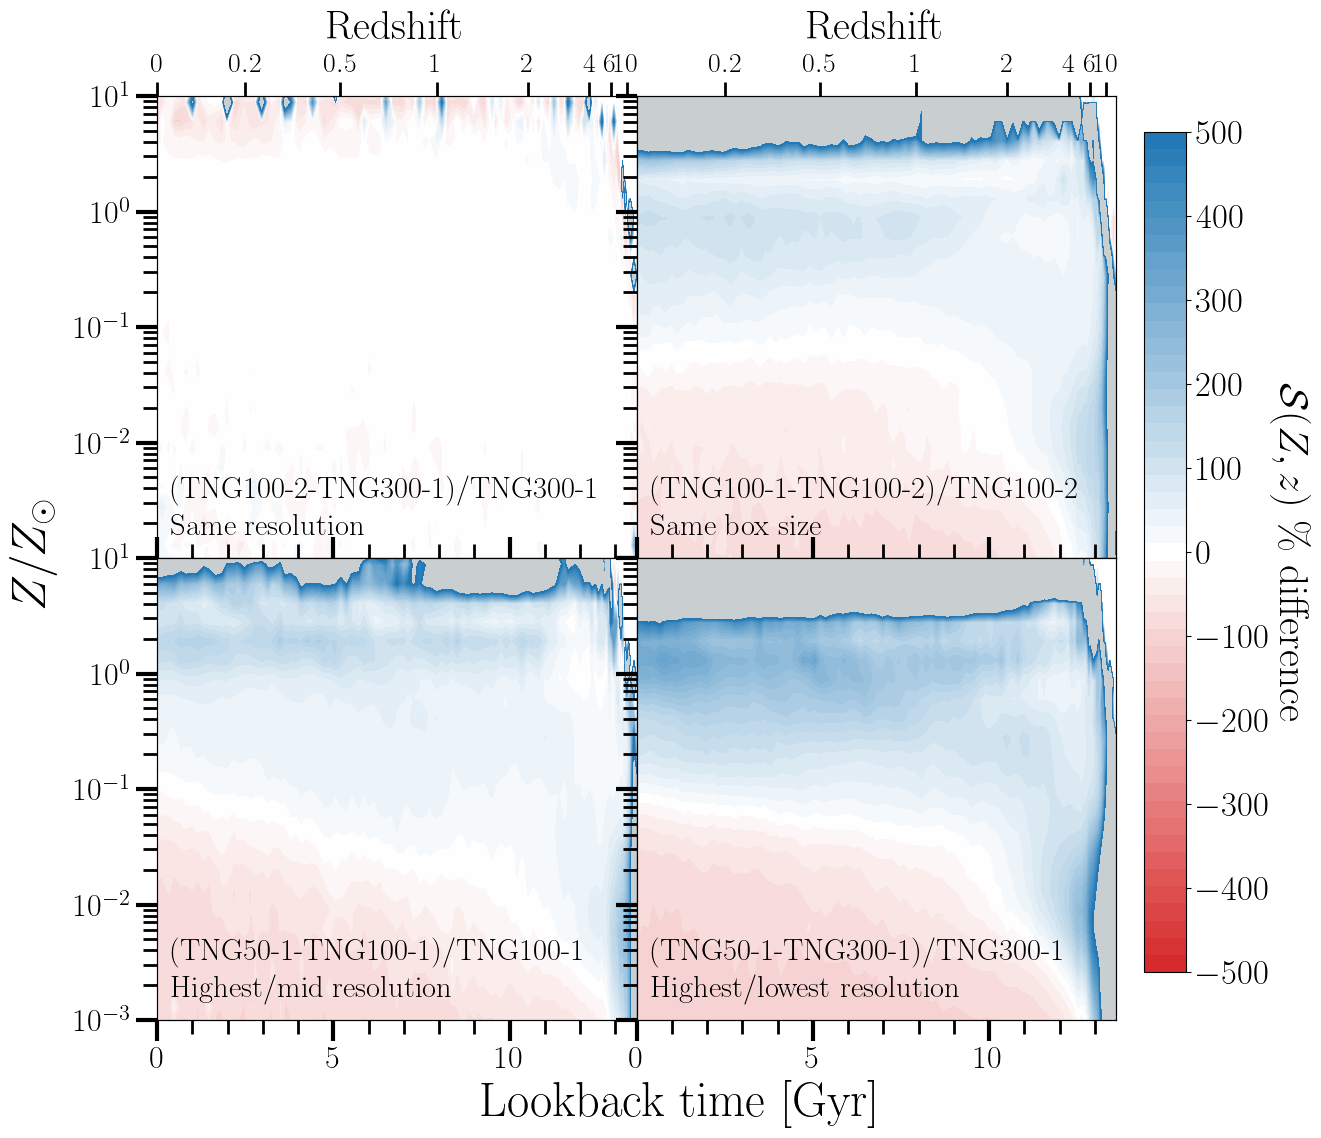

In [21]:
Zsun = 0.014 #Solar metallicity
cmap = matplotlib.colors.LinearSegmentedColormap.from_list('', ['tab:red', 'white', 'tab:blue'])
levels = 30

fig, ax = plt.subplots(figsize = (14,12))
fig.subplots_adjust(wspace=0, hspace=0)

tnglabels = ['(%s-%s)/%s'%(tngs[2],tngs[3],tngs[3]), '(%s-%s)/%s'%(tngs[1],tngs[2],tngs[2]), '(%s-%s)/%s'%(tngs[0],tngs[1], tngs[1]), '(%s-%s)/%s'%(tngs[0],tngs[3], tngs[3])]


for n, tng in enumerate(numerator):
    ax = plt.subplot(ceil(len(tngs)/2), 2, n + 1)
    print(ax)

    #Plot data and is model is given plot model
    #numerator[n][numerator[n] < 1e-7] = 1e-7
    #denominator[n][denominator[n] < 1e-7] = 1e-7
    percenterr = (numerator[n]-denominator[n])/denominator[n] * 100
    levels = np.linspace(-500, 500, 50)
    data = ax.contourf(LookbacktimesTNG[n], metalsTNG[n]/Zsun, percenterr, levels=levels, cmap=cmap)
    ax.text(0.03, 0.13, tnglabels[n], transform=ax.transAxes, fontsize=22, color='black')
    ax.text(0.03, 0.05, tnglabels2[n], transform=ax.transAxes, fontsize=22, color='black')
    ax.set_facecolor("#c9ced1")

    #Set yscale, TNG version label on each plot, and axis labels
    ax.set_yscale('log')
    fig.supxlabel('Lookback time [Gyr]', y=0.02, fontsize=35)
    fig.supylabel(r'$Z/Z_{\rm{\odot}}$', x=0.02, fontsize=35)
    ax.tick_params(axis='both', which='major', labelsize=23)
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.tick_params(length=15, width=3, which='major')
    ax.tick_params(length=10, width=2, which='minor')

    #Set redshift ticks; make sure they don't overlap
    ax2 = ax.twiny()
    if n==1:
        redshift_tick_list = [0.2, 0.5, 1.0, 2, 4, 6, 10]
    else:
        redshift_tick_list = [0, 0.2, 0.5, 1.0, 2, 4, 6, 10]

    #Hide overlapping tick labels
    if n==0:
        ax.set_yticks([1e-2, 1e-1, 1e0, 1e1])
        ax.set_yticklabels(['$\\mathdefault{10^{-2}}$', '$\\mathdefault{10^{-1}}$', '$\\mathdefault{10^{0}}$', '$\\mathdefault{10^{1}}$'])

    #Hide tick labels depending on how many subplots are in the figure, and their configuration
    if n%2==0:
        if len(tngs) > 2 and n<len(tngs)-2: #if left column with more than two subplots, but not last row, hide ticks and labels
            ax.tick_params(axis='x',  which='both', labelbottom=False, direction='in')
    else:
        if len(tngs) ==2: #if right subplot with only one row, hide left ticks on the left side
            ax.tick_params(axis='both',  which='both', labelleft=False)
        elif len(tngs) > 2 and n<len(tngs)-2: #if right subplot with more than one row, hide left and bottom ticks
            ax.tick_params(axis='y',  which='both', labelleft=False)
            ax.tick_params(axis='x',  which='both', labelbottom=False, direction='in')
        else: #if last right subplot, hide left label
            ax.tick_params(axis='both',  which='both', labelleft=False)

    #Set redshift axis labels for only first row of subplots
    if n < 2: 
        ax2.set_xlabel('Redshift', fontsize = 30, labelpad=10)
        ax2.set_xticks([cosmo.lookback_time(z).value for z in redshift_tick_list])
        ax2.set_xticklabels(['${:g}$'.format(z) for z in redshift_tick_list])
    else:
        ax2.set_xlabel('', fontsize = 30)
        ax2.set_xticks([cosmo.lookback_time(z).value for z in redshift_tick_list*0])
        ax2.set_xticklabels(['${:g}$'.format(z) for z in redshift_tick_list*0])

    ax2.tick_params(axis='both', which='major', labelsize=20)
    ax2.tick_params(length=10, width=2, which='major')

    #Set limits for horizontal (lookback time) and vertical (metallicity) axes
    ax.set_xlim(0, 13.6) #not always want to set xlimits, so empty if not using any; in lookback time
    ax2.set_xlim(0, 13.6) #in lookback time
    ax.set_ylim(10**-3, 10) #defaults for TNG data are Z=10**-1 to Z=10**1

    

#Set up the colorbar
fig.subplots_adjust(right=0.81)
cbar_ax = fig.add_axes([0.83, 0.15, 0.03, 0.7])
ticks = np.arange(-500, 501, 100)
cbar = fig.colorbar(data, cax=cbar_ax, ticks=ticks)
cbar.ax.tick_params(labelsize=25)

cbar.set_label(r'$\mathcal{S}(Z,z)$ \% difference', rotation=270, fontsize=30, labelpad=30);
fig.savefig('figures/SFRD_Z_z_percentdifference.pdf', bbox_inches='tight')

## BBH populations

In [49]:
import init_values as In
import popsummary
import h5py as h5
In.init()
data_dir    =  str(paths.data) +'/'
save_loc = str(paths.figures) + '/'
COMPASfilename = 'COMPAS_Output_wWeights.h5'

filenames = ['SFRMetallicityFromGasWithMetalsTNG50-1.hdf5', 'SFRMetallicityFromGasWithMetalsTNG100-1.hdf5', 'SFRMetallicityFromGasWithMetalsTNG100-2.hdf5', 'SFRMetallicityFromGasWithMetalsTNG300-1.hdf5',]
data_rates = ['data_Rate_info_TNG50-1_z20.h5',  'data_Rate_info_TNG100-1_z20.h5', 'data_Rate_info_TNG100-2_z20.h5', 'data_Rate_info_TNG300-1_z20.h5']

#Plot setup
labels = ['TNG50-1', 'TNG100-1', 'TNG100-2', 'TNG300-1', 'TNG50-1',  'TNG100-2', 'TNG300-1'] 
linestyles = ['-', '-', '--', '-', '-', '--', '-', ':', ':']
z_order = [2, 2, 3, 2, 3, 4, 3, 5, 5]
linestyles2 = ['-', '--', ':', '-.']
lineweights = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]

line_styles = ['solid', 'dashed', 'dotted']
tmin = 0.0
tmax = 13.7
z_of_mass_dist = [0.2, 1, 2, 4, 6, 8]
data_colors = [ "#1275AF", '#F76FDD',  "#900849", '#98CB4F', 'blue', 'purple', 'green', 'red', 'orange']
colormap = sns.color_palette('viridis_r', as_cmap=True)
colormap_gray = sns.color_palette('gray_r', as_cmap=True)

Couldnt open /Users/sashalvna/Research/Fit_SFRD_TNG/data//test_best_fit_parameters.txt


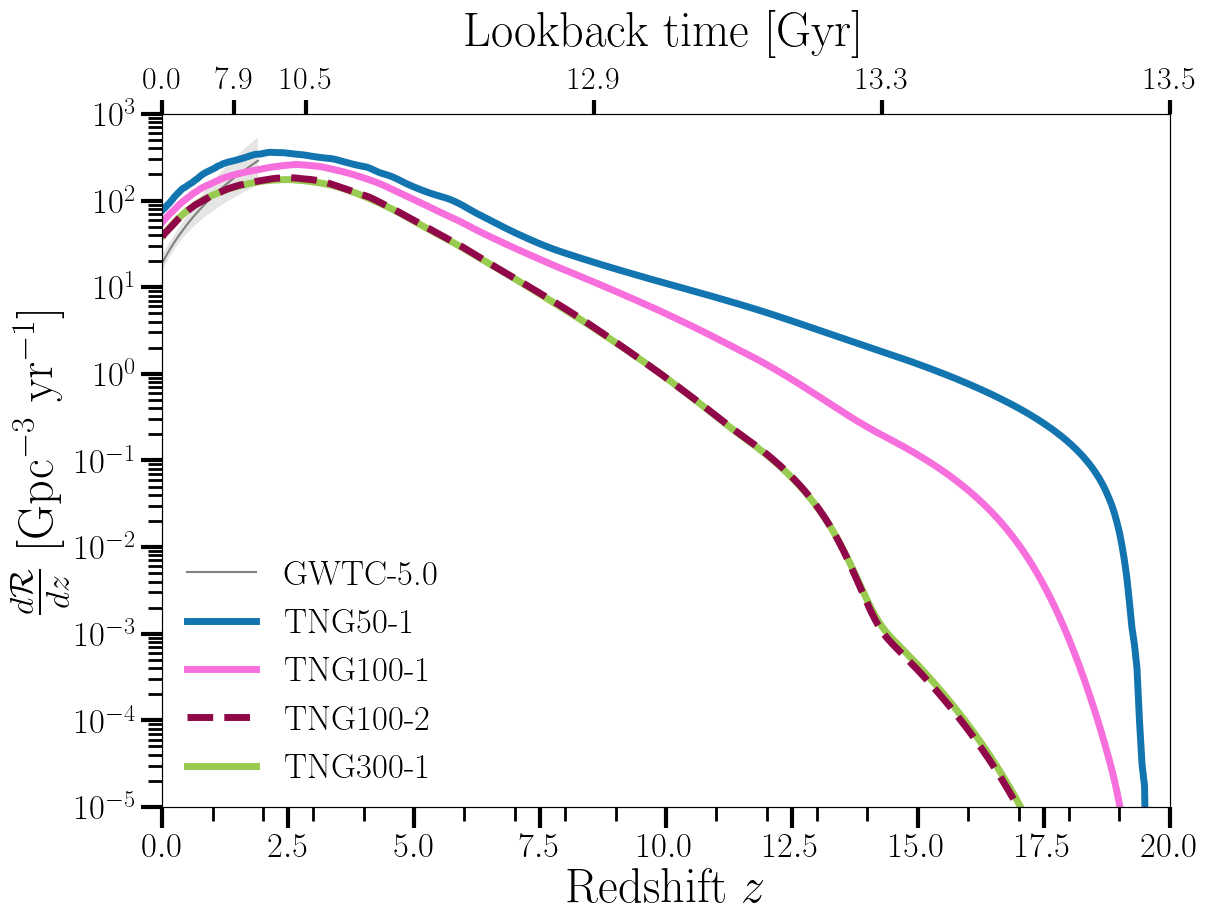

In [50]:
fig, ax = plt.subplots(figsize=[13, 9])

color_plpeak = 'grey'#'#1f78b4'
#default gwtc-5
strong_bbh_O4b = popsummary.popresult.PopulationResult(fname=data_dir+f'gwtc5_updated_default_mmax_mass_TwoPeakBrokenPowerLawSmoothedMassDistribution_redshift_PowerLawRedshift_magnitude_iid_spin_magnitude_gaussian_tilt_iid_spin_orientation_popsummary_result.h5')
strong_bbh_O4b_z_grid, strong_bbh_O4b_Rz = strong_bbh_O4b.get_rates_on_grids('redshift')
strong_bbh_O4b_z_grid = strong_bbh_O4b_z_grid.reshape((strong_bbh_O4b_z_grid.size, ))
ax.semilogy(strong_bbh_O4b_z_grid, np.quantile(strong_bbh_O4b_Rz, 0.5, axis = 0), 
        color=color_plpeak, label='GWTC-5.0', zorder=0)
ax.fill_between(strong_bbh_O4b_z_grid, np.quantile(strong_bbh_O4b_Rz, 0.05, axis = 0), 
            np.quantile(strong_bbh_O4b_Rz, 0.95, axis = 0), 
            color=color_plpeak, edgecolor=None, alpha=0.2, zorder=0)

lookbacktimes = []
redshifts = []
merger_rates = []
for i, rfile in enumerate(data_rates):
    with h5.File(data_dir + rfile ,'r') as File:
        redshift      = File[list(File.keys())[0]]['redshifts'][()]
        merger_rate    = File[list(File.keys())[0]]['merger_rate'][()]
        lookbacktime = cosmo.lookback_time(redshift).value
    
    total_merger_rate = np.sum(merger_rate, axis=0)
    plt.plot(redshift, total_merger_rate, label=labels[i], ls=linestyles[i], lw=5, color=data_colors[i], zorder=z_order[i])
    redshifts.append(redshift)
    merger_rates.append(total_merger_rate)
    lookbacktimes.append(lookbacktime)

ax.set_xlim(0, 20)
ax.set_ylim(1e-5, 1e3)
ax.set_xlabel('Redshift $z$', fontsize=35)
ax.set_ylabel(r'$\frac{d\mathcal{R}}{dz} \ [\rm Gpc^{-3} \ yr^{-1}]$', fontsize=35)
fig.legend(bbox_to_anchor=(0.12, 0.1), fontsize=25, loc="lower left", frameon=False)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_yscale('log')

ax2 = ax.twiny() 
redshift_tick_list = [0, 1, 2, 6, 10, 14]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')

plt.savefig('figures/merger_rates_allTNGs.pdf', format="pdf", bbox_inches='tight', dpi=300, transparent=True)

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/3044654070.py:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], merger_rates[2]/merger_rates[3], label='%s/%s'%(labels[2],labels[3]), lw=5, color=data_colors_all[0], zorder=4)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/3044654070.py:6: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], merger_rates[1]/merger_rates[2], label='%s/%s'%(labels[1],labels[2]), lw=5, color=data_colors_all[1], zorder=3)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/3044654070.py:7: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], merger_rates[0]/merger_rates[1], label='%s/%s'%(labels[0],labels[1]), lw=5, color=data_colors_all[2], zorder=2)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/3044654070.py:8: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], merger_rates[0]/merger_rates

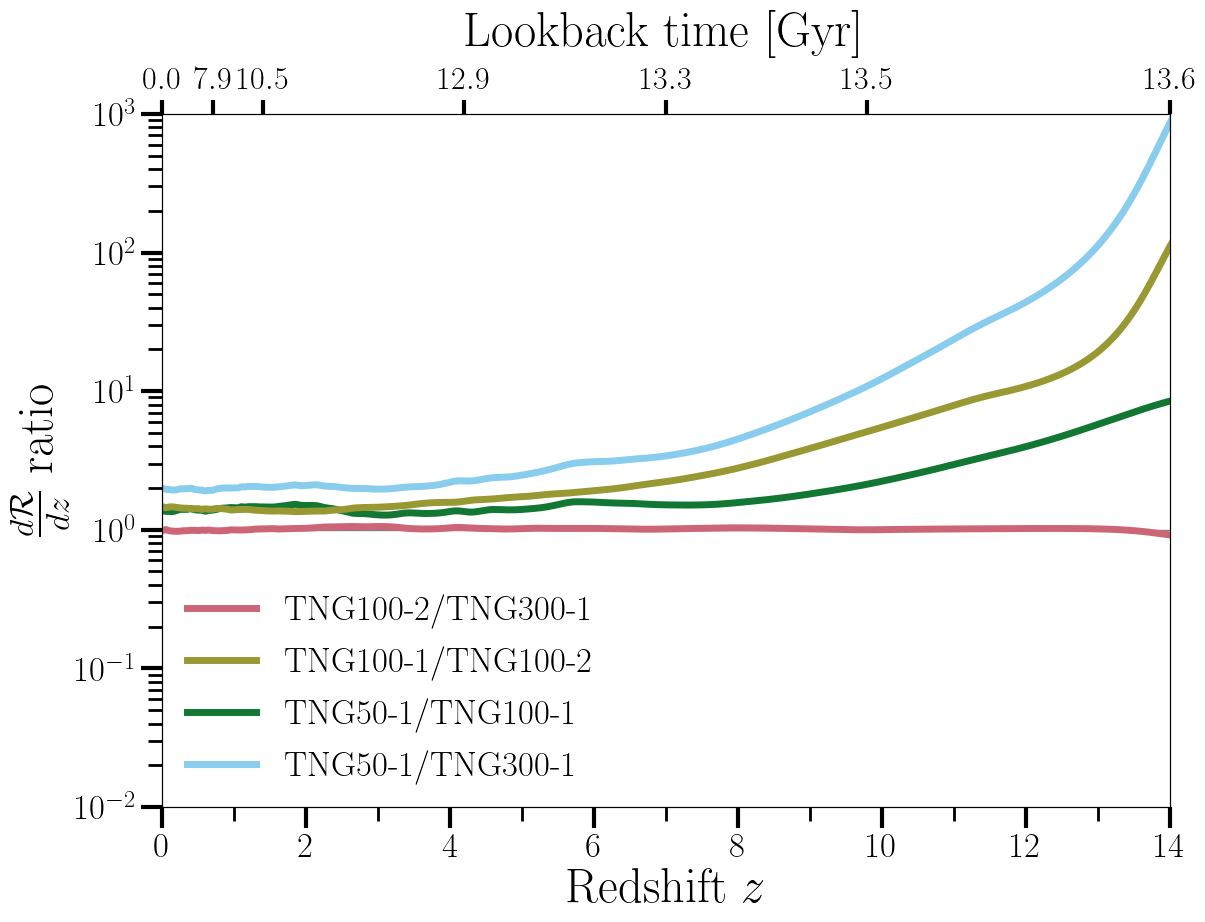

In [51]:
fig, ax = plt.subplots(figsize=[13, 9])

ax.axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1

plt.plot(redshifts[0], merger_rates[2]/merger_rates[3], label='%s/%s'%(labels[2],labels[3]), lw=5, color=data_colors_all[0], zorder=4)
plt.plot(redshifts[0], merger_rates[1]/merger_rates[2], label='%s/%s'%(labels[1],labels[2]), lw=5, color=data_colors_all[1], zorder=3)
plt.plot(redshifts[0], merger_rates[0]/merger_rates[1], label='%s/%s'%(labels[0],labels[1]), lw=5, color=data_colors_all[2], zorder=2)
plt.plot(redshifts[0], merger_rates[0]/merger_rates[3], label='%s/%s'%(labels[0],labels[3]), lw=5, color=data_colors_all[3], zorder=1)

ax.set_xlim(0, 14)
ax.set_ylim(1e-2, 1e3)
ax.set_xlabel('Redshift $z$', fontsize=35)
ax.set_ylabel(r'$\frac{d\mathcal{R}}{dz}$ ratio', fontsize=35)
fig.legend(bbox_to_anchor=(0.12, 0.1), fontsize=25, loc="lower left", frameon=False)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_yscale('log')

ax2 = ax.twiny() 
redshift_tick_list = [0, 1, 2, 6, 10, 14, 20]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')



plt.savefig('figures/merger_rates_ratio_allTNGs.pdf', format="pdf", bbox_inches='tight', dpi=300, transparent=True)

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1786254557.py:5: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], ((merger_rates[2]-merger_rates[3])/merger_rates[3]) *100, label='(%s-%s)/%s'%(labels[2],labels[3], labels[3]), lw=5, color=data_colors_all[0], zorder=4)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1786254557.py:6: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], ((merger_rates[1]-merger_rates[2])/merger_rates[2]) *100, label='(%s-%s)/%s'%(labels[1],labels[2], labels[2]), lw=5, color=data_colors_all[1], zorder=3)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/1786254557.py:7: RuntimeWarning: invalid value encountered in divide
  plt.plot(redshifts[0], ((merger_rates[0]-merger_rates[1])/merger_rates[1]) *100, label='(%s-%s)/%s'%(labels[0],labels[1], labels[1]), lw=5, color=data_colors_all[2], zorder=2)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705

5.5267003591318 %
29500.959359418168 %


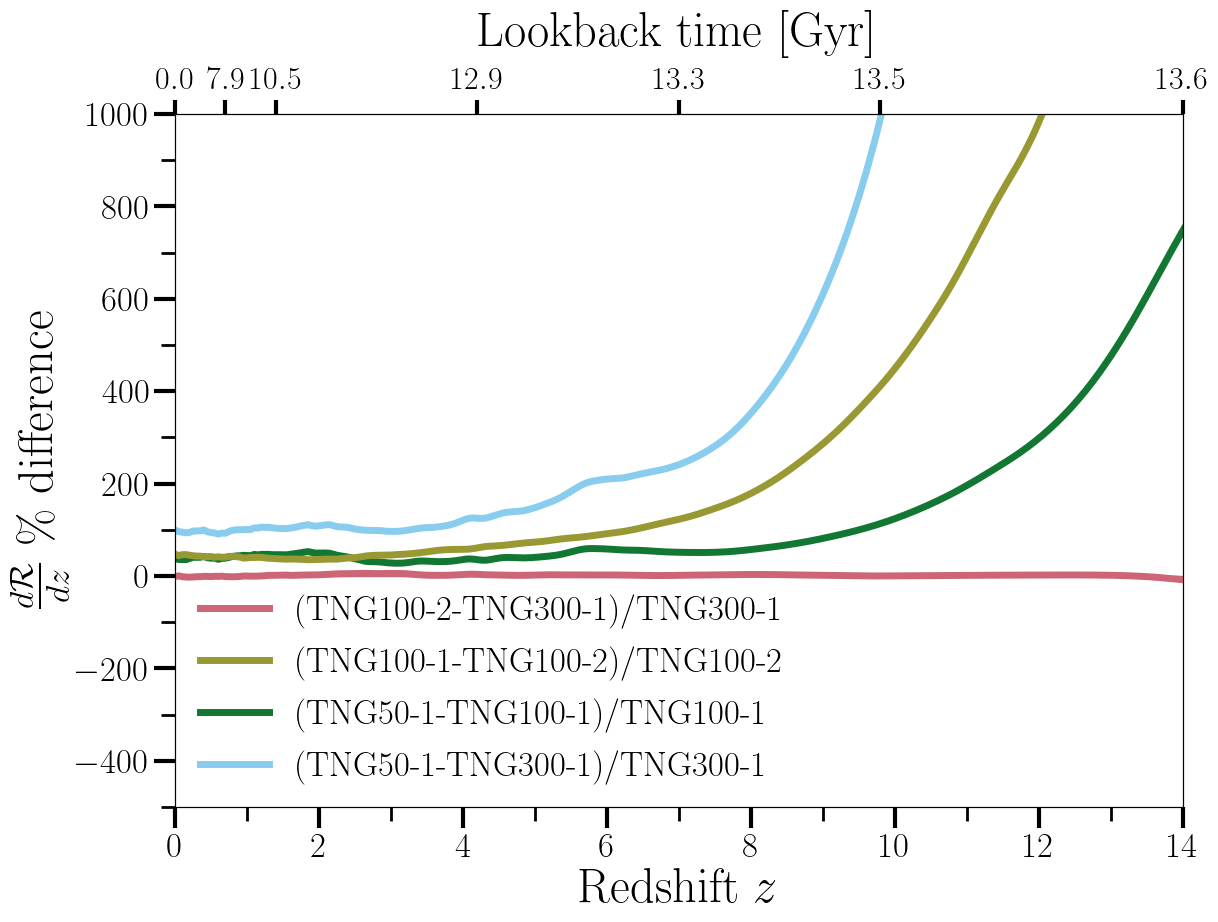

In [52]:
fig, ax = plt.subplots(figsize=[13, 9])

ax.axhline(y=0, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1

plt.plot(redshifts[0], ((merger_rates[2]-merger_rates[3])/merger_rates[3]) *100, label='(%s-%s)/%s'%(labels[2],labels[3], labels[3]), lw=5, color=data_colors_all[0], zorder=4)
plt.plot(redshifts[0], ((merger_rates[1]-merger_rates[2])/merger_rates[2]) *100, label='(%s-%s)/%s'%(labels[1],labels[2], labels[2]), lw=5, color=data_colors_all[1], zorder=3)
plt.plot(redshifts[0], ((merger_rates[0]-merger_rates[1])/merger_rates[1]) *100, label='(%s-%s)/%s'%(labels[0],labels[1], labels[1]), lw=5, color=data_colors_all[2], zorder=2)
plt.plot(redshifts[0], ((merger_rates[0]-merger_rates[3])/merger_rates[3]) *100, label='(%s-%s)/%s'%(labels[0],labels[3], labels[3]), lw=5, color=data_colors_all[3], zorder=1)

ax.set_xlim(0, 14)
ax.set_ylim(-500, 1000)
ax.set_xlabel('Redshift $z$', fontsize=35)
ax.set_ylabel(r'$\frac{d\mathcal{R}}{dz}$ \% difference', fontsize=35)
fig.legend(bbox_to_anchor=(0.12, 0.1), fontsize=25, loc="lower left", frameon=False)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(100))

ax2 = ax.twiny() 
redshift_tick_list = [0, 1, 2, 6, 10, 14, 20]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')

print(np.amax((merger_rates[2][:-40]-merger_rates[3][:-40])/merger_rates[3][:-40]) *100, '%')
print(np.amax((merger_rates[1][:-100]-merger_rates[2][:-100])/merger_rates[2][:-100]) *100, '%')

plt.savefig('figures/merger_rates_percentdiff_allTNGs.pdf', format="pdf", bbox_inches='tight', dpi=300, transparent=True)

Reading  /Users/sashalvna/Research/Fit_SFRD_TNG/data/COMPAS_Output_wWeights.h5
Done with reading DCO data for this file :)
Path to simulation /data_Rate_info_TNG50-1_z20.h5 0
Path to simulation /data_Rate_info_TNG100-1_z20.h5 1
Path to simulation /data_Rate_info_TNG100-2_z20.h5 2
Path to simulation /data_Rate_info_TNG300-1_z20.h5 3


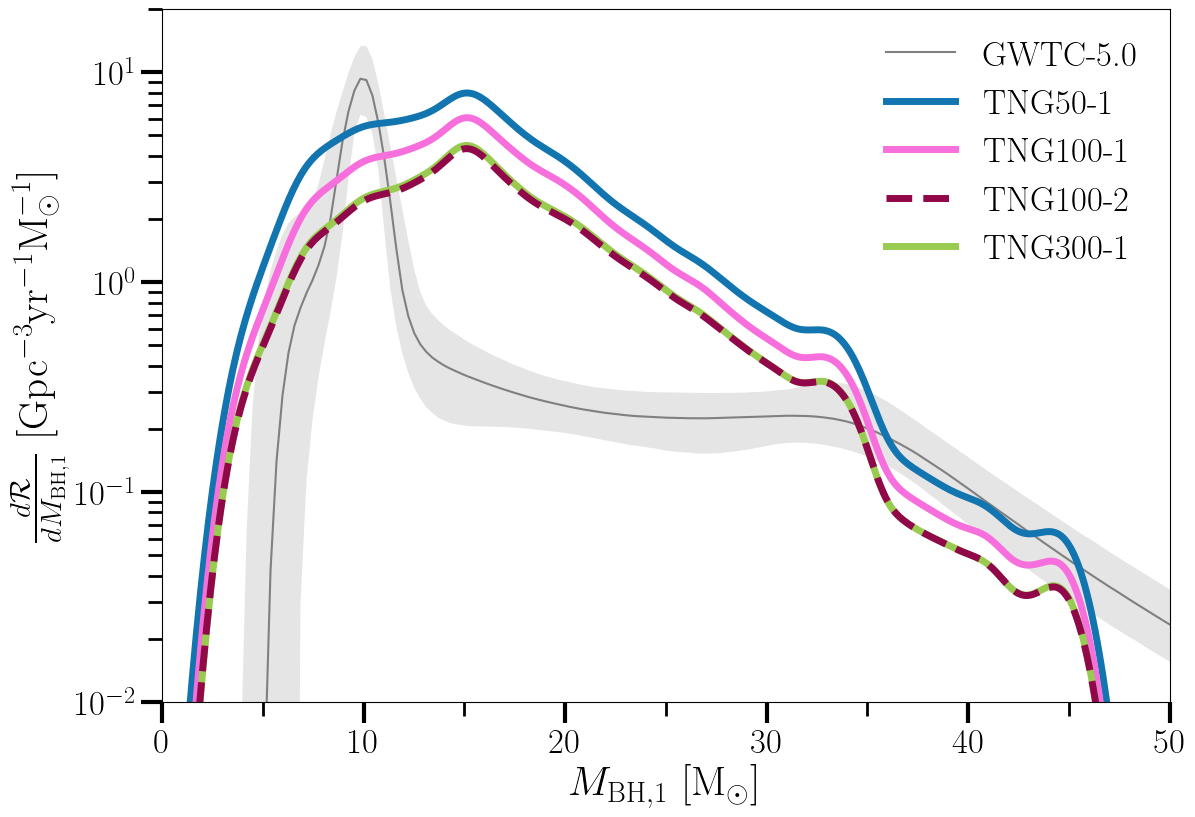

In [ ]:
from scipy import stats
import MassDistHelperFunctions as mfunc

z=0.2

TNGpaths = []
for i in data_rates:
    TNGpaths.append('/'+i)

fig, ax = plt.subplots(figsize=[13, 9])
bins = np.arange(0.,55,2.5)
x_lim=(0.,50)
y_lim = (1e-2,20)
xlabel = r'$M_{\mathrm{BH, 1}} \ \rm [M_{\odot}]$'
ylabel = r'$\frac{d\mathcal{R}}{dM_{\mathrm{BH, 1} }} \ \mathrm{[Gpc^{-3}yr^{-1}M^{-1}_{\odot}]}$'

# GWTC-5 
color_plpeak = 'grey'#'#1f78b4'
strong_bbh_O4b = popsummary.popresult.PopulationResult(fname=data_dir+f'gwtc5_updated_default_mmax_mass_TwoPeakBrokenPowerLawSmoothedMassDistribution_redshift_PowerLawRedshift_magnitude_iid_spin_magnitude_gaussian_tilt_iid_spin_orientation_popsummary_result.h5')
strong_bbh_O4b_m1_grid, strong_bbh_O4b_Rm1 = strong_bbh_O4b.get_rates_on_grids('mass_1')
strong_bbh_O4b_m1_grid = strong_bbh_O4b_m1_grid.reshape((strong_bbh_O4b_m1_grid.size, ))
zeval = 0.2
redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))
ax.plot(strong_bbh_O4b_m1_grid, 
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.5, axis=0),
        color=color_plpeak, label='GWTC-5.0', lw=1.5, zorder=1)
ax.fill_between(strong_bbh_O4b_m1_grid, 
                np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.05, axis=0),
            np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.95, axis=0), 
                color=color_plpeak, edgecolor=None, alpha=0.2, zorder=0)

DCO = mfunc.read_data(loc = data_dir +str(COMPASfilename))

#Loop over TNGs
nplot = 0
massdists = []
for i, tngpath in enumerate(TNGpaths):
    print('Path to simulation', tngpath, i)

    #Reading Rate data 
    with h5.File(data_dir + tngpath ,'r') as File:
        redshifts_data = File[list(File.keys())[0]]['redshifts'][()]
        DCO_mask = File[list(File.keys())[0]]['DCOmask'][()] # Mask from DCO to merging systems  
        intrinsic_rate_density = File[list(File.keys())[0]]['merger_rate'][()]

    CEcount = 'CE_Event_Counter'
    #first bring it to the same shape as the rate table
    merging_BBH    = DCO[DCO_mask]
    #apply the additional mask based on your prefs
    channel_bool = np.full(len(merging_BBH), True)
    # we exclude CHE systems
    not_CHE  = merging_BBH['Stellar_Type@ZAMS(1)'] != 16
    BBH_bool = np.logical_and(merging_BBH['Stellar_Type(1)'] == 14, merging_BBH['Stellar_Type(2)'] == 14)

    merging_BBH         = merging_BBH[BBH_bool * not_CHE  * channel_bool]
    Red_intr_rate_dens  = intrinsic_rate_density[BBH_bool* not_CHE * channel_bool, :]

    #Calculate average rate density per z-bin
    x_vals              = merging_BBH['M_moreMassive']
    i_redshift = np.where(redshifts_data == z)[0][0] # Rate at redshift 0.2
    Weights             = Red_intr_rate_dens[:, i_redshift]#crude_rate_density[:,0]
    Weights[Weights < 0] = 0

    # Get the Hist    
    hist, bin_edge = np.histogram(x_vals, weights = Weights, bins=bins)

    # And the KDE
    kernel = stats.gaussian_kde(x_vals, bw_method='scott', weights=Weights)

    x_KDE = np.arange(0.1,50.,0.1)
    KDEy_vals =  kernel(x_KDE)*sum(hist) #re-normalize the KDE
    ax.plot(x_KDE, KDEy_vals, color=data_colors[nplot], lw= 5, ls=linestyles[nplot], label = labels[nplot], zorder=z_order[i])
    massdists.append(KDEy_vals)
    nplot += 1
    
#########################################
# plot values
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.set_xlabel(xlabel, fontsize = 30)
ax.set_ylabel(ylabel, fontsize = 30)
ax.set_yscale('log')

fig.legend(bbox_to_anchor=(0.9, 0.88), fontsize=25, frameon=False)
fig.savefig('figures/massdist_allTNGs_%s.pdf'%z,format="pdf", bbox_inches='tight', dpi=300, transparent="transparent")

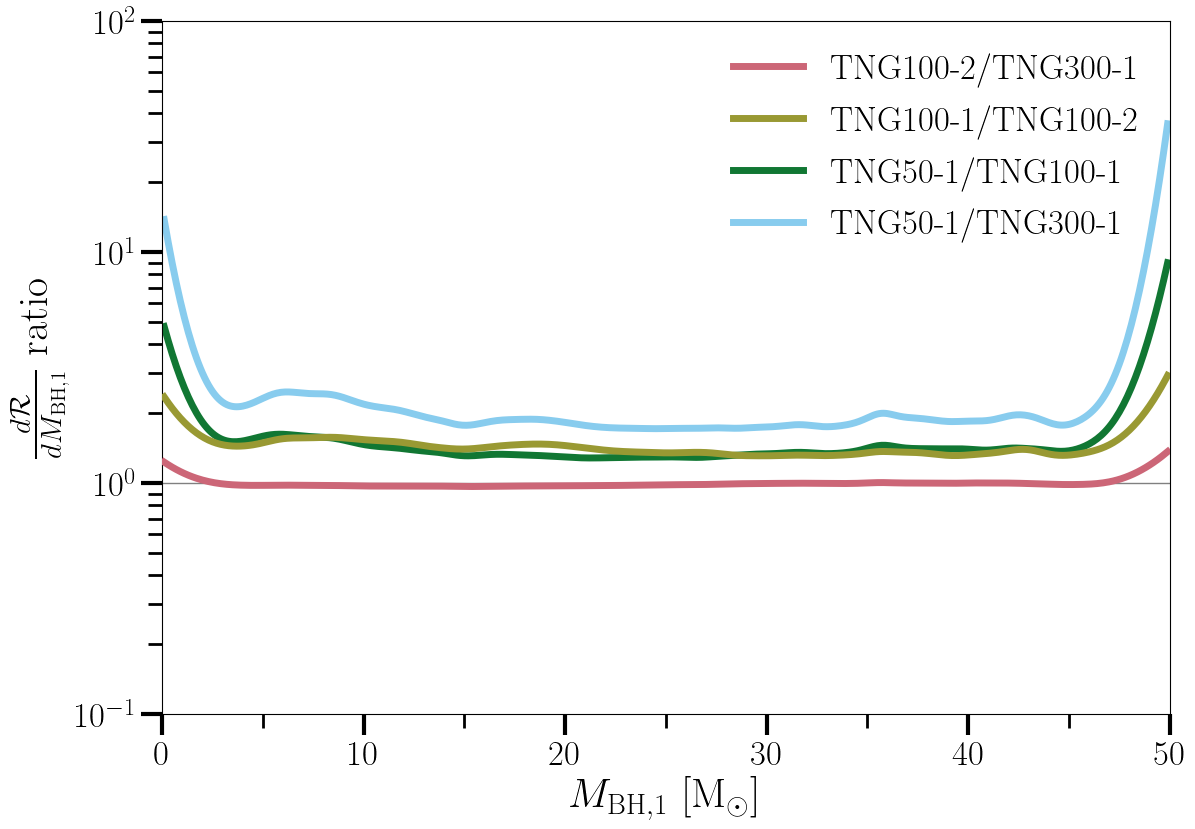

In [54]:
fig, ax = plt.subplots(figsize=[13, 9])
bins = np.arange(0.,55,2.5)
x_lim=(0.,50)
y_lim = (1e-1,100)
xlabel = r'$M_{\mathrm{BH, 1}} \ \rm [M_{\odot}]$'
ylabel = r'$\frac{d\mathcal{R}}{dM_{\mathrm{BH, 1} }}$ ratio'

ax.axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1

ax.plot(x_KDE, massdists[2]/massdists[3], color=data_colors_all[0], lw= 5, label = '%s/%s'%(labels[2],labels[3]), zorder=4)
ax.plot(x_KDE, massdists[1]/massdists[2], color=data_colors_all[1], lw= 5, label = '%s/%s'%(labels[1],labels[2]), zorder=3)
ax.plot(x_KDE, massdists[0]/massdists[1], color=data_colors_all[2], lw= 5, label = '%s/%s'%(labels[0],labels[1]), zorder=2)
ax.plot(x_KDE, massdists[0]/massdists[3], color=data_colors_all[3], lw= 5, label = '%s/%s'%(labels[0],labels[3]), zorder=1)

    
#########################################
# plot values
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.set_xlabel(xlabel, fontsize = 30)
ax.set_ylabel(ylabel, fontsize = 30)
ax.set_yscale('log')

fig.legend(bbox_to_anchor=(0.9, 0.88), fontsize=25, frameon=False)
fig.savefig('figures/compare_massdist_allTNGs_%s.pdf'%z,format="pdf", bbox_inches='tight', dpi=300, transparent="transparent")

3.141791390665765 %
57.792226736718256 %


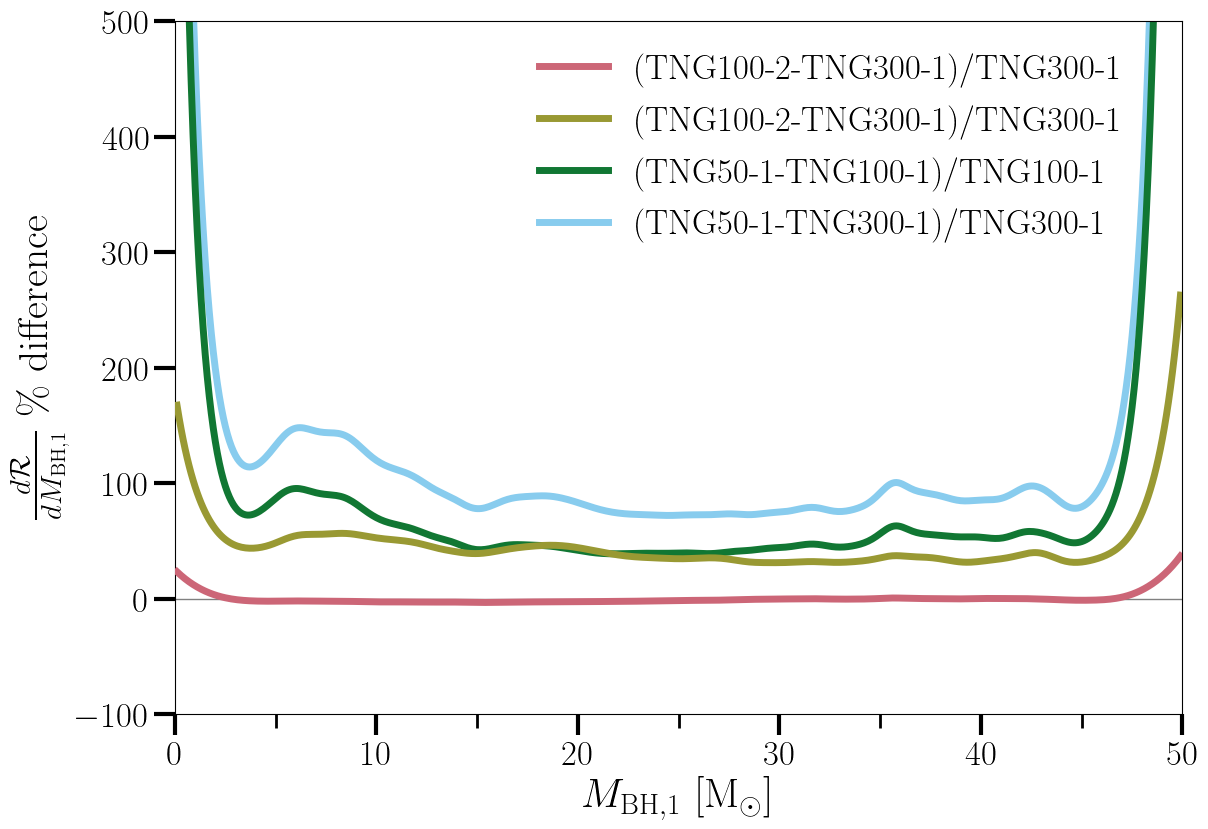

In [55]:
fig, ax = plt.subplots(figsize=[13, 9])
bins = np.arange(0.,55,2.5)
x_lim=(0.,50)
y_lim = (-100,500)
xlabel = r'$M_{\mathrm{BH, 1}} \ \rm [M_{\odot}]$'
ylabel = r'$\frac{d\mathcal{R}}{dM_{\mathrm{BH, 1} }}$ \% difference'

ax.axhline(y=0, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1

ax.plot(x_KDE, ((massdists[2]-massdists[3])/massdists[3]) *100, color=data_colors_all[0], lw= 5, label = '(%s-%s)/%s'%(labels[2],labels[3], labels[3]), zorder=4)
ax.plot(x_KDE, ((massdists[1]-massdists[2])/massdists[3]) *100, color=data_colors_all[1], lw= 5, label = '(%s-%s)/%s'%(labels[2],labels[3], labels[3]), zorder=3)
ax.plot(x_KDE, ((massdists[0]-massdists[1])/massdists[3]) *100, color=data_colors_all[2], lw= 5, label = '(%s-%s)/%s'%(labels[0],labels[1], labels[1]), zorder=2)
ax.plot(x_KDE, ((massdists[0]-massdists[3])/massdists[3]) *100, color=data_colors_all[3], lw= 5, label = '(%s-%s)/%s'%(labels[0],labels[3], labels[3]), zorder=1)
    
#########################################
# plot values
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.set_xlabel(xlabel, fontsize = 30)
ax.set_ylabel(ylabel, fontsize = 30)
#ax.set_yscale('log')

print(np.amax((massdists[2][25:-25]-massdists[3][25:-25])/massdists[3][25:-25]) *100, '%')
print(np.amax((massdists[1][25:-25]-massdists[2][25:-25])/massdists[2][25:-25]) *100, '%')


fig.legend(bbox_to_anchor=(0.88, 0.88), fontsize=25, frameon=False)
fig.savefig('figures/compare_massdist_allTNGs_percentdiff_%s.pdf'%z,format="pdf", bbox_inches='tight', dpi=300, transparent="transparent")

/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/285301009.py:30: RuntimeWarning: invalid value encountered in divide
  ax[0,0].plot(redshifts[0], merger_rates[2]/merger_rates[3], label='%s/%s, same resolution'%(labels[2],labels[3]), lw=5, color=data_colors_all[0], zorder=4)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/285301009.py:31: RuntimeWarning: invalid value encountered in divide
  ax[0,0].plot(redshifts[0], merger_rates[1]/merger_rates[2], label='%s/%s, same box size'%(labels[1],labels[2]), lw=5, color=data_colors_all[1], zorder=3)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/285301009.py:32: RuntimeWarning: invalid value encountered in divide
  ax[0,0].plot(redshifts[0], merger_rates[0]/merger_rates[1], label='%s/%s'%(labels[0],labels[1]), lw=5, color=data_colors_all[2], zorder=2)
/var/folders/h0/sdzcqrx17fj53mqjr65dvvjh0000gn/T/ipykernel_73705/285301009.py:33: RuntimeWarning: invalid value encountered in divide
  ax[0,0]

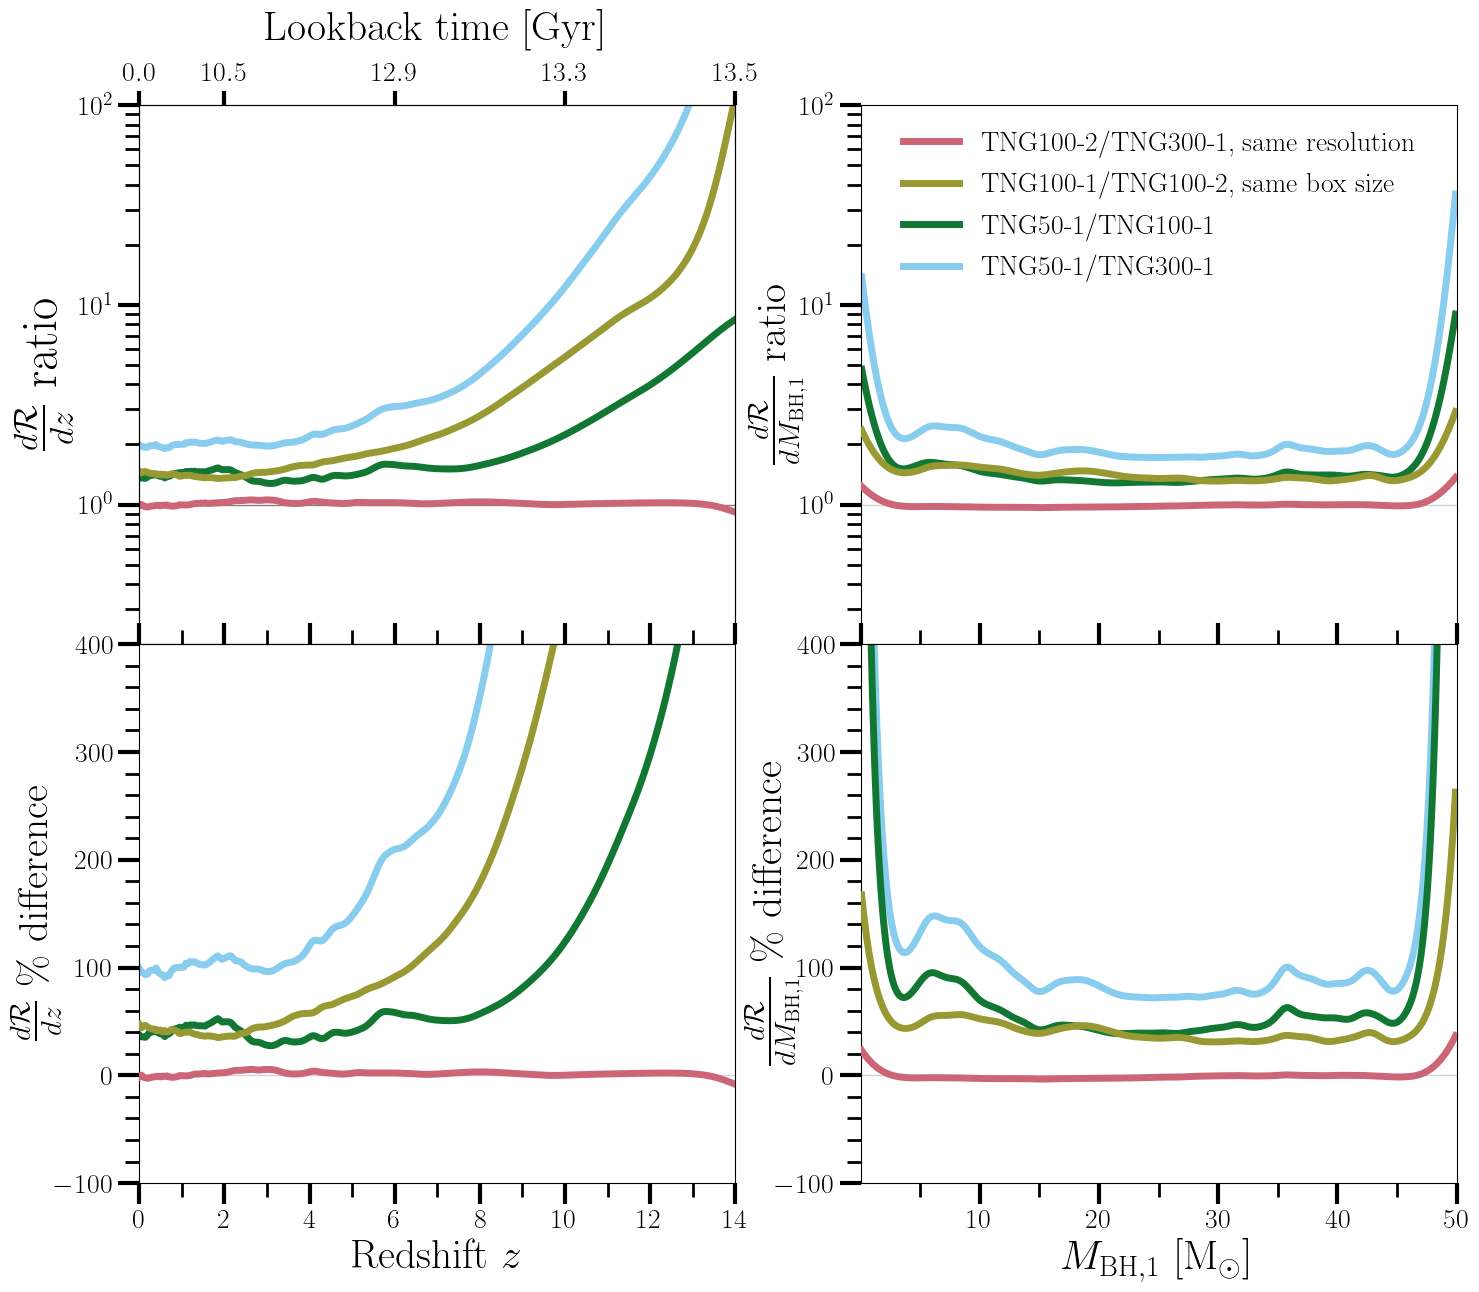

In [56]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize = (17,14))
fig.subplots_adjust(hspace=0, wspace=0.21)

#############################################
#merger rate ratio
ax[0,0].axhline(y=1, linewidth=1, color='gray', zorder=0) #add horizontal line at y=1
ax[0,0].tick_params(axis='both', which='major', labelsize=20) 
ax[0,0].xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[0,0].tick_params(length=15, width=3, which='major')
ax[0,0].tick_params(length=10, width=2, which='minor')
ax[0,0].tick_params(axis='x', which='major', direction='in') 
ax[0,0].tick_params(axis='x', which='minor', direction='in') 
ax[0,0].tick_params(axis='x',  which='both', labelbottom=False)
ax[0,0].set_yscale('log')

#set up second x axis
ax2 = ax[0,0].twiny()
redshift_tick_list = [0, 2, 6, 10, 14]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 20)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 30, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=20)
ax2.tick_params(length=10, width=3, which='major')


ax2.set_xlim(0, 14) 
ax[0,0].set_xlim(0, 14)
ax[0,0].set_ylim(2e-1, 1e2)
ax[0,0].set_ylabel(r'$\frac{d\mathcal{R}}{dz}$ ratio', fontsize=35)
ax[0,0].plot(redshifts[0], merger_rates[2]/merger_rates[3], label='%s/%s, same resolution'%(labels[2],labels[3]), lw=5, color=data_colors_all[0], zorder=4)
ax[0,0].plot(redshifts[0], merger_rates[1]/merger_rates[2], label='%s/%s, same box size'%(labels[1],labels[2]), lw=5, color=data_colors_all[1], zorder=3)
ax[0,0].plot(redshifts[0], merger_rates[0]/merger_rates[1], label='%s/%s'%(labels[0],labels[1]), lw=5, color=data_colors_all[2], zorder=2)
ax[0,0].plot(redshifts[0], merger_rates[0]/merger_rates[3], label='%s/%s'%(labels[0],labels[3]), lw=5, color=data_colors_all[3], zorder=1)

#############################################
#merger rate percent error
ax[1,0].axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax[1,0].tick_params(axis='both', which='major', labelsize=20)
ax[1,0].tick_params(length=15, width=3, which='major')
ax[1,0].tick_params(length=10, width=2, which='minor')
ax[1,0].xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[1,0].yaxis.set_minor_locator(ticker.MultipleLocator(20))

#Set limits for horizontal axis
ax[1,0].set_xlim(0, 14)
ax[1,0].set_ylim(-100, 400)
ax[1,0].set_xlabel('Redshift $z$', fontsize=30)
ax[1,0].set_ylabel(r'$\frac{d\mathcal{R}}{dz}$ \% difference', fontsize=30, labelpad=-5)

ax[1,0].plot(redshifts[0], ((merger_rates[2]-merger_rates[3])/merger_rates[3]) *100, lw=5, color=data_colors_all[0], zorder=4)
ax[1,0].plot(redshifts[0], ((merger_rates[1]-merger_rates[2])/merger_rates[2]) *100, lw=5, color=data_colors_all[1], zorder=3)
ax[1,0].plot(redshifts[0], ((merger_rates[0]-merger_rates[1])/merger_rates[1]) *100, lw=5, color=data_colors_all[2], zorder=2)
ax[1,0].plot(redshifts[0], ((merger_rates[0]-merger_rates[3])/merger_rates[3]) *100, lw=5, color=data_colors_all[3], zorder=1)

#############################################
#mass dist ratio
Zsun = 0.014
ax[0,1].axhline(y=1, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax[0,1].tick_params(axis='both', which='major', labelsize=20)
ax[0,1].tick_params(length=15, width=3, which='major')
ax[0,1].tick_params(length=10, width=2, which='minor')
ax[0,1].tick_params(axis='x', which='major', direction='in')
ax[0,1].tick_params(axis='x', which='minor', direction='in')
ax[0,1].xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax[0,1].yaxis.set_minor_locator(ticker.MultipleLocator(1))
ax[0,1].tick_params(axis='x',  which='both', labelbottom=False)
ax[0,1].set_yscale('log')
ax[0,1].set_ylabel(r'$\frac{d\mathcal{R}}{dM_{\mathrm{BH, 1} }}$ ratio', fontsize = 30, labelpad=-5)

#Set limits for horizontal axis
ax[0,1].set_xlim(0, 50)
ax[0,1].set_ylim(2e-1, 1e2)

ax[0,1].plot(x_KDE, massdists[2]/massdists[3], color=data_colors_all[0], lw= 5, zorder=4)
ax[0,1].plot(x_KDE, massdists[1]/massdists[2], color=data_colors_all[1], lw= 5,  zorder=3)
ax[0,1].plot(x_KDE, massdists[0]/massdists[1], color=data_colors_all[2], lw= 5,  zorder=2)
ax[0,1].plot(x_KDE, massdists[0]/massdists[3], color=data_colors_all[3], lw= 5, zorder=1)

#############################################
#mass dist percent error
ax[1,1].axhline(y=0, linewidth=1, color='lightgray', zorder=0) #add horizontal line at y=1
ax[1,1].tick_params(axis='both', which='major', labelsize=20)
ax[1,1].tick_params(length=15, width=3, which='major')
ax[1,1].tick_params(length=10, width=2, which='minor')
ax[1,1].xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax[1,1].yaxis.set_minor_locator(ticker.MultipleLocator(20))
ax[1,1].set_xlabel(r'$M_{\mathrm{BH, 1}} \ \rm [M_{\odot}]$', fontsize = 30)
ax[1,1].set_ylabel(r'$\frac{d\mathcal{R}}{dM_{\mathrm{BH, 1} }}$ \% difference', fontsize = 30, labelpad=-20)

ax[1,1].set_xlim(0.01,50)
ax[1,1].set_ylim(-100,400)

ax[1,1].plot(x_KDE, ((massdists[2]-massdists[3])/massdists[3]) *100, color=data_colors_all[0], lw= 5,  zorder=4)
ax[1,1].plot(x_KDE, ((massdists[1]-massdists[2])/massdists[3]) *100, color=data_colors_all[1], lw= 5,  zorder=3)
ax[1,1].plot(x_KDE, ((massdists[0]-massdists[1])/massdists[3]) *100, color=data_colors_all[2], lw= 5, zorder=2)
ax[1,1].plot(x_KDE, ((massdists[0]-massdists[3])/massdists[3]) *100, color=data_colors_all[3], lw= 5,  zorder=1)
    

fig.legend(fontsize = 20, frameon=False, bbox_to_anchor=(0.89, 0.88))
fig.savefig('figures/compareBBHpop_allTNGs.pdf', format="pdf",  bbox_inches='tight', dpi=300, transparent='transparent')

## Check delay times/high z rates

In [ ]:
import astropy.units as u
from scipy.interpolate import interp1d

Reading  /Users/sashalvna/Research/Fit_SFRD_TNG/data/COMPAS_Output_wWeights.h5
Done with reading DCO data for this file :)
296.3366738328341 Myr
2.95857927964806e-11


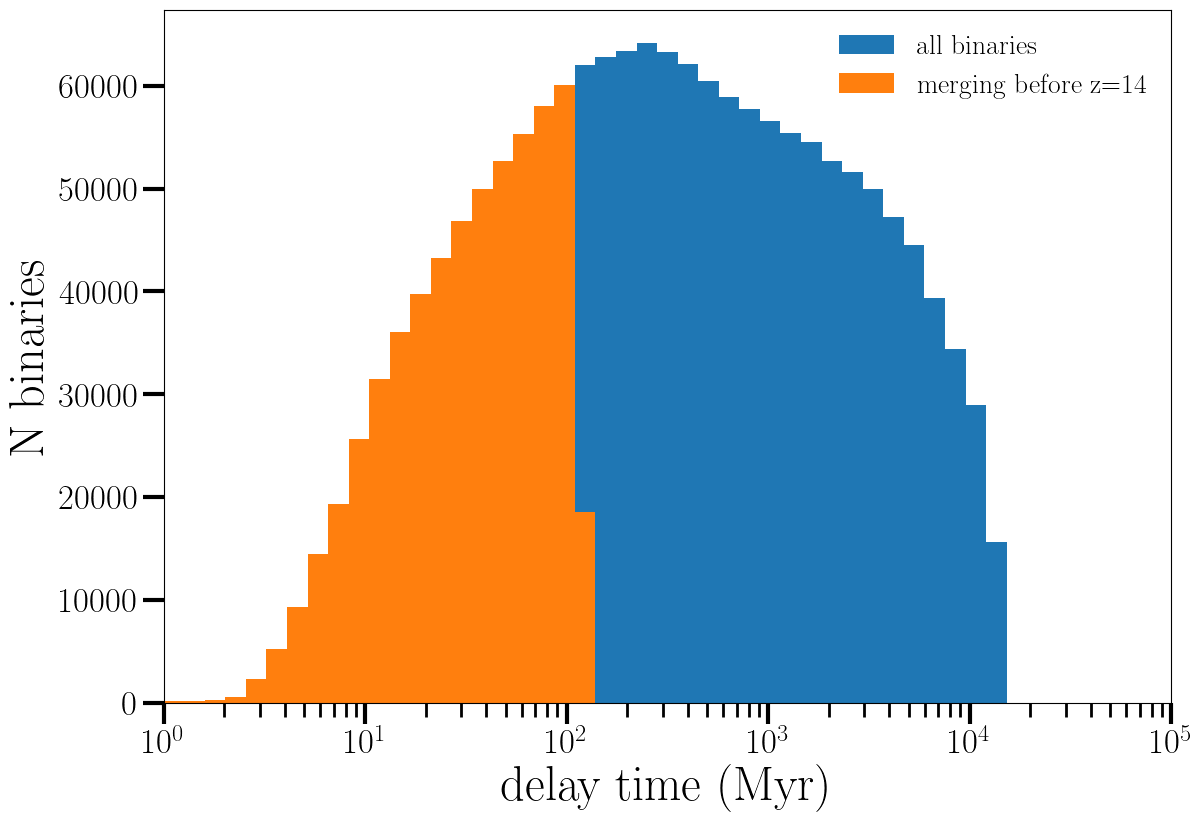

In [ ]:
fig, ax = plt.subplots(figsize=[13, 9])

z_15 = []
for i, rfile in enumerate([data_rates[2]]):
    with h5.File(data_dir + rfile ,'r') as File:
        redshift      = File[list(File.keys())[0]]['redshifts'][()]
        merger_rate    = File[list(File.keys())[0]]['merger_rate'][()]
        seeds    = File[list(File.keys())[0]]['SEED'][()]
        DCO_mask    = File[list(File.keys())[0]]['DCOmask'][()]
        lookbacktime = cosmo.lookback_time(redshift).value

    DCO = mfunc.read_data(loc = data_dir +str(COMPASfilename))
    merging_BBH = DCO[DCO_mask]
    not_CHE  = merging_BBH['Stellar_Type@ZAMS(1)'] != 16
    BBH_bool = np.logical_and(merging_BBH['Stellar_Type(1)'] == 14, merging_BBH['Stellar_Type(2)'] == 14)
    merging_BBH         = merging_BBH[BBH_bool * not_CHE]
    merging_BBH_merger_rate  = merger_rate[BBH_bool * not_CHE, :]
    merging_BBH_seeds =  seeds[BBH_bool * not_CHE]

    with h5.File(data_dir + '/' + COMPASfilename ,'r') as File:
                    metallicities_compas = File['BSE_Double_Compact_Objects']['Metallicity@ZAMS(1)'][()] #same metallicity for both stars
                    COMPAS_delay_times = File['BSE_Double_Compact_Objects']['Coalescence_Time'][()]#Myr
                    time = File['BSE_Double_Compact_Objects']['Time'][()] #Myr
                    seeds_compas = File['BSE_Double_Compact_Objects']['SEED'][()]


    #filter formation redshift and metallicity by the seeds we want
    mask_merging_DCOs = np.isin(seeds_compas, merging_BBH_seeds)
    seeds_DCOs = seeds_compas[mask_merging_DCOs]
    metallicities_compas = metallicities_compas[mask_merging_DCOs]
    COMPAS_delay_times = COMPAS_delay_times[mask_merging_DCOs]
    time = time[mask_merging_DCOs]

    
    age_merger = cosmo.age(14).to(u.Myr).value
    age_first_sfr = cosmo.age(20).to(u.Myr).value
    print(age_merger, 'Myr')
    age_of_formation = age_merger - COMPAS_delay_times
    age_of_formation_mask = (age_of_formation >= age_first_sfr) 
    age_of_formation_masked = age_of_formation[age_of_formation_mask]
    COMPAS_delay_times_z14 = COMPAS_delay_times[age_of_formation_mask]

    seeds_DCO_masked = seeds_DCOs[age_of_formation_mask]
    metallicities_compas_masked = metallicities_compas[age_of_formation_mask]

    mask_z14= np.isin(merging_BBH_seeds, seeds_DCO_masked)
    merger_rate_z14 = merging_BBH_merger_rate[mask_z14]
    redshifts_mask = np.where(redshift>14)[0]
    redshifts_z14 = redshift[redshifts_mask]
    merger_rate_z14 = merger_rate_z14[:, redshifts_mask]

    bins = np.logspace(0, 5, 50)

    print(min(COMPAS_delay_times))
    
    plt.hist(COMPAS_delay_times, bins=bins, label='all binaries' )
    plt.hist(COMPAS_delay_times_z14, bins=bins, label='merging before z=14')

ax.set_xlim(1e0, 1e5)
ax.set_xlabel('delay time (Myr)', fontsize=35)
ax.set_ylabel(r'N binaries', fontsize=35)
ax.legend(fontsize=20,frameon=False)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.set_xscale('log')
#ax.set_yscale('log')


plt.savefig('figures/delay_times.pdf', format="pdf", bbox_inches='tight', dpi=300, transparent=True)

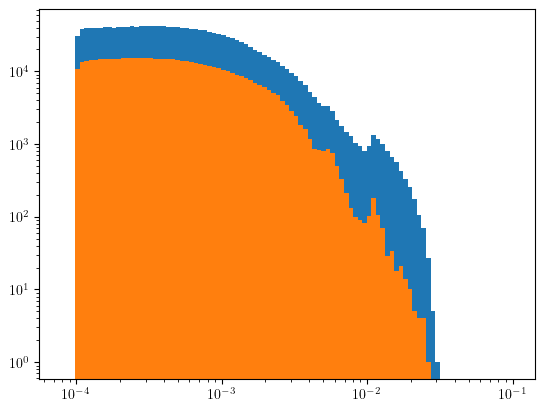

In [ ]:
metalbins = np.logspace(-4.1, -1, 100)
plt.hist(metallicities_compas, bins=metalbins, label='all binaries' )
plt.hist(metallicities_compas_masked, bins=metalbins, label='merging before z=17.5')
plt.xscale('log')
plt.yscale('log')

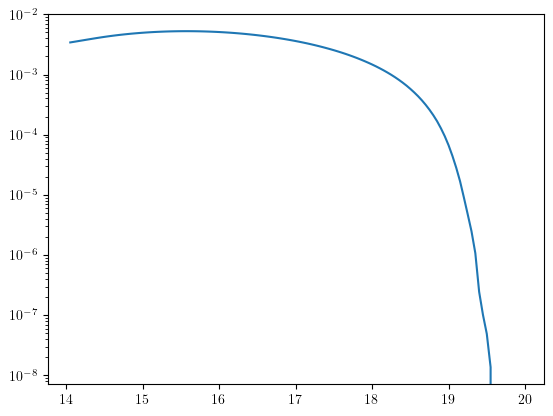

In [ ]:
plt.plot(redshifts_z14, np.sum(merger_rate_z14, axis=0))
plt.yscale('log')

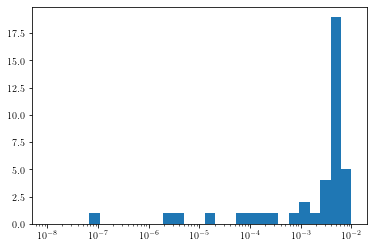

In [ ]:
bins=np.logspace(-8, -2, 30)
plt.hist(np.sum(merger_rate_z14, axis=0), bins=bins)
#plt.yscale('log')
plt.xscale('log')

## Normalized BBH populations

The TNG50-1 merger rate at z=0.0 is:  76.92865780478066
The TNG100-1 merger rate at z=0.0 is:  55.96689452713732
The TNG100-2 merger rate at z=0.0 is:  38.05137530752933
The TNG300-1 merger rate at z=0.0 is:  38.59338605047365


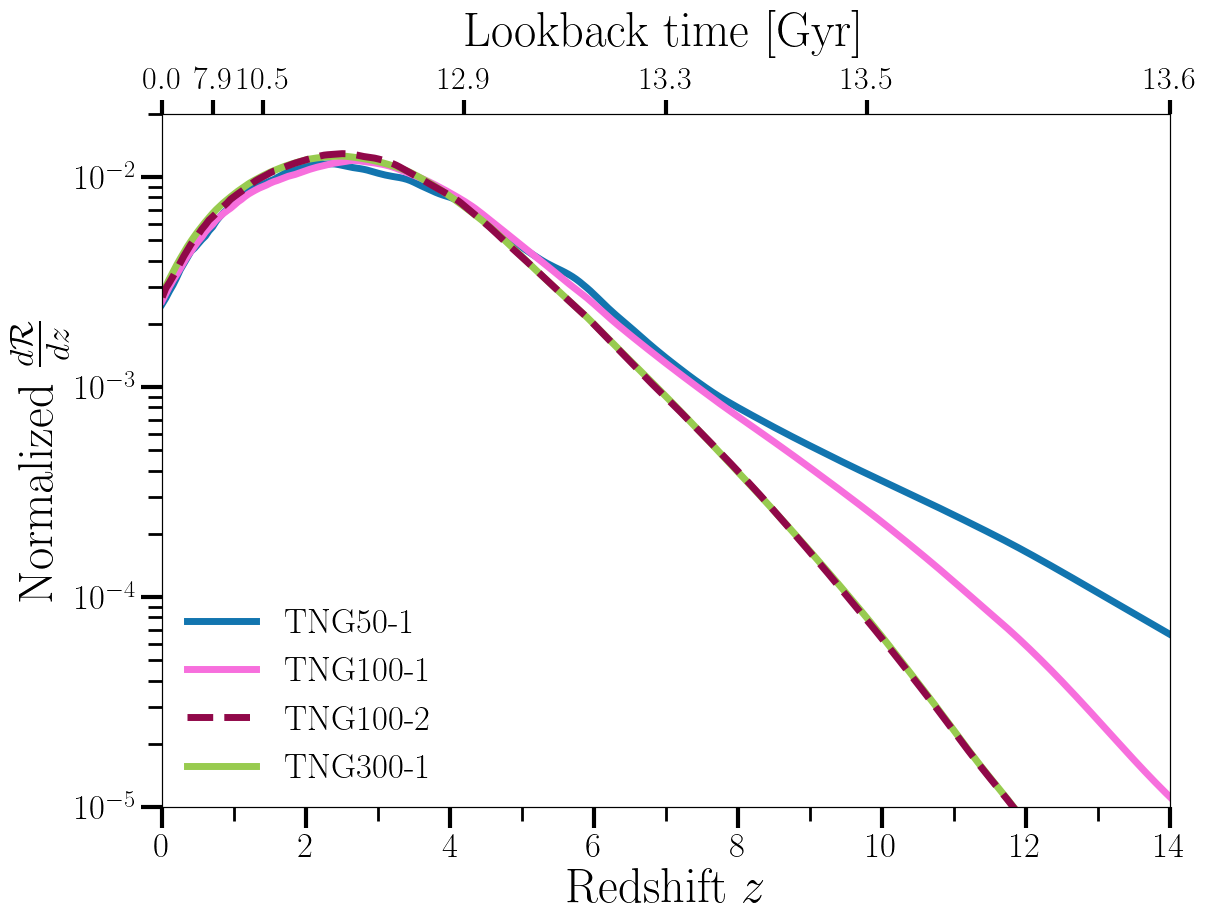

In [61]:
fig, ax = plt.subplots(figsize=[13, 9])

redshifts = []
merger_rates = []
for i, rfile in enumerate(data_rates):
    with h5.File(data_dir + rfile ,'r') as File:
        redshift      = File[list(File.keys())[0]]['redshifts'][()]
        merger_rate    = File[list(File.keys())[0]]['merger_rate'][()]

    total_merger_rate = np.sum(merger_rate, axis=0)
    plt.plot(redshift, total_merger_rate/np.sum(total_merger_rate), label=labels[i], ls=linestyles[i], lw=5, color=data_colors[i], zorder=z_order[i])
    redshifts.append(redshift)
    merger_rates.append(total_merger_rate)
    print("The %s merger rate at z=%s is: "%(labels[i], redshift[0]), total_merger_rate[0])

ax.set_xlim(0, 14)
ax.set_ylim(1e-5, 2e-2)
ax.set_xlabel('Redshift $z$', fontsize=35)
ax.set_ylabel(r'Normalized $\frac{d\mathcal{R}}{dz}$', fontsize=35)
fig.legend(bbox_to_anchor=(0.12, 0.1), fontsize=25, loc="lower left", frameon=False)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.set_yscale('log')

ax2 = ax.twiny() 
redshift_tick_list = [0, 1, 2, 6, 10, 14, 20]#[0,0.1, 0.25, 0.5, 1.0, 10]
ax2.set_xticks([z for z in redshift_tick_list])
ax2.set_xticklabels(['${:.1f}$'.format(cosmo.lookback_time(z).value) for z in redshift_tick_list], fontsize = 25)
ax2.set_xlabel('Lookback time [Gyr]', fontsize = 35, labelpad=15)
ax2.tick_params(axis='both', which='major', labelsize=23)
ax2.tick_params(length=10, width=3, which='major')

plt.savefig('figures/normalized_merger_rates_allTNGs.pdf', format="pdf", bbox_inches='tight', dpi=300, transparent=True)

Reading  /Users/sashalvna/Research/Fit_SFRD_TNG/data/COMPAS_Output_wWeights.h5
Done with reading DCO data for this file :)
Path to simulation /data_Rate_info_TNG50-1_z20.h5 0
Path to simulation /data_Rate_info_TNG100-1_z20.h5 1
Path to simulation /data_Rate_info_TNG100-2_z20.h5 2
Path to simulation /data_Rate_info_TNG300-1_z20.h5 3


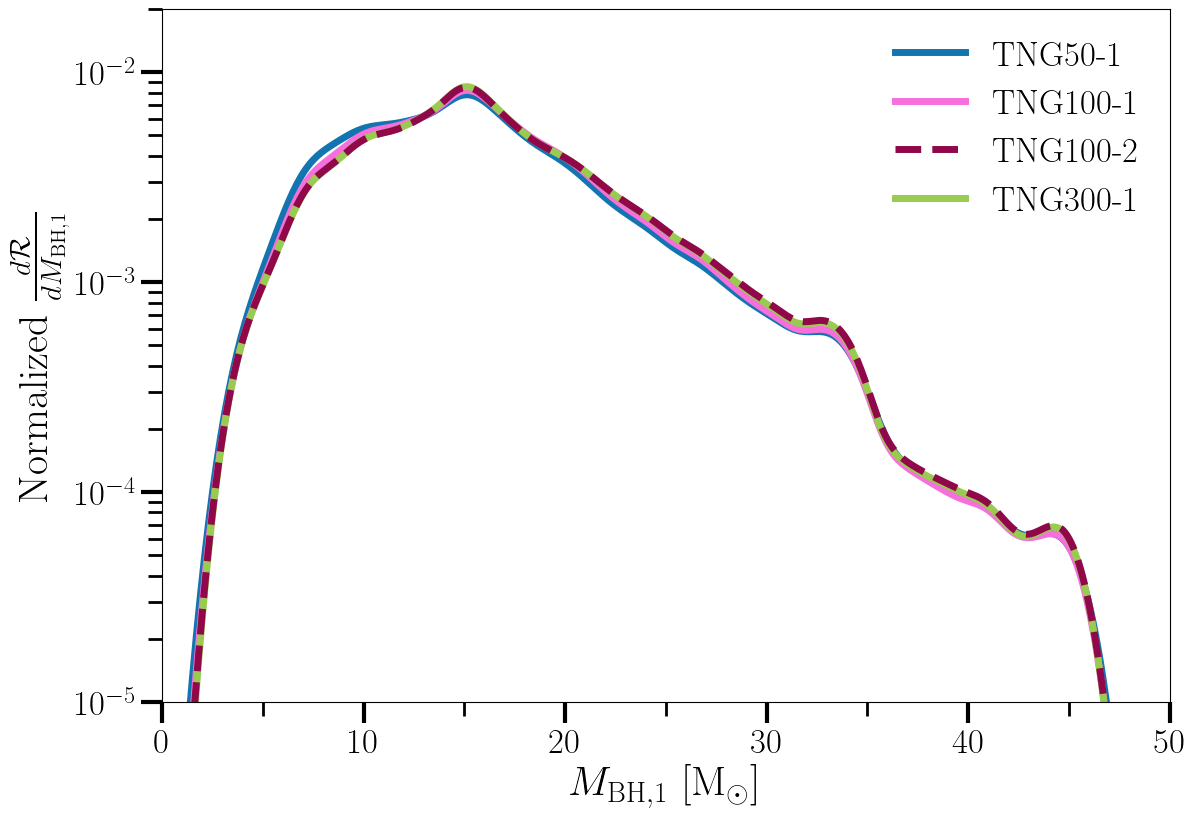

In [63]:
z=0.2
fig, ax = plt.subplots(figsize=[13, 9])
bins = np.arange(0.,55,2.5)
x_lim=(0.,50)
y_lim = (1e-5,2e-2)
xlabel = r'$M_{\mathrm{BH, 1}} \ \rm [M_{\odot}]$'
ylabel = r'Normalized $\frac{d\mathcal{R}}{dM_{\mathrm{BH, 1} }}$'

DCO = mfunc.read_data(loc = data_dir +str(COMPASfilename))

#Loop over TNGs
nplot = 0
massdists = []
for i, tngpath in enumerate(TNGpaths):
    print('Path to simulation', tngpath, i)

    #Reading Rate data 
    with h5.File(data_dir + tngpath ,'r') as File:
        redshifts = File[list(File.keys())[0]]['redshifts'][()]
        DCO_mask = File[list(File.keys())[0]]['DCOmask'][()] # Mask from DCO to merging systems  
        intrinsic_rate_density = File[list(File.keys())[0]]['merger_rate'][()]

    CEcount = 'CE_Event_Counter'
    #first bring it to the same shape as the rate table
    merging_BBH    = DCO[DCO_mask]
    #apply the additional mask based on your prefs
    channel_bool = np.full(len(merging_BBH), True)
    # we exclude CHE systems
    not_CHE  = merging_BBH['Stellar_Type@ZAMS(1)'] != 16
    BBH_bool = np.logical_and(merging_BBH['Stellar_Type(1)'] == 14, merging_BBH['Stellar_Type(2)'] == 14)

    merging_BBH         = merging_BBH[BBH_bool * not_CHE  * channel_bool]
    Red_intr_rate_dens  = intrinsic_rate_density[BBH_bool* not_CHE * channel_bool, :]

    #Calculate average rate density per z-bin
    x_vals              = merging_BBH['M_moreMassive']
    i_redshift = np.where(redshifts == z)[0][0] # Rate at redshift 0.2
    Weights             = Red_intr_rate_dens[:, i_redshift]#crude_rate_density[:,0]
    Weights[Weights < 0] = 0

    # Get the Hist    
    hist, bin_edge = np.histogram(x_vals, weights = Weights, bins=bins)

    # And the KDE
    kernel = stats.gaussian_kde(x_vals, bw_method='scott', weights=Weights)

    x_KDE = np.arange(0.1,50.,0.1)
    KDEy_vals =  kernel(x_KDE)*sum(hist) #re-normalize the KDE
    ax.plot(x_KDE, KDEy_vals/np.sum(KDEy_vals), color=data_colors[nplot], lw= 5, ls=linestyles[nplot], label = labels[nplot], zorder=z_order[i])
    massdists.append(KDEy_vals)
    nplot += 1
    
#########################################
# plot values
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)
ax.tick_params(axis='both', which='major', labelsize=25)
ax.tick_params(length=15, width=3, which='major')
ax.tick_params(length=10, width=2, which='minor')
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))

ax.set_xlabel(xlabel, fontsize = 30)
ax.set_ylabel(ylabel, fontsize = 30)
ax.set_yscale('log')

fig.legend(bbox_to_anchor=(0.9, 0.88), fontsize=25, frameon=False)
fig.savefig('figures/normalized_massdist_allTNGs_%s.pdf'%z,format="pdf", bbox_inches='tight', dpi=300, transparent="transparent")